# PDAN8412 – Programming for Data Analytics 2
## Convolutional Neural Networks

**Student:** Elton Tati  
**Student Number:** ST10158190

**Dataset Name:** Oxford-IIIT Pet Dataset

**Dataset Description:** A collection of 7,349 officially listed images representing 37 categories of cats and dogs (12 cat breeds and 25 dog breeds).

**Dataset Size:** Approximately 800 MB (images and annotations combined). The local image inventory initially contained 7,390 files; after duplicate removal, 7,360 unique images remained. The analysis used 7,349 images from the official training/validation and test splits.

**Dataset Source:** University of Oxford – Visual Geometry Group (VGG)

**Official Dataset Link:** https://www.robots.ox.ac.uk/~vgg/data/pets/

**Images Download:** https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz

**Annotations Download:** https://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz

**Dataset Reference:**  
Parkhi, O. M., Vedaldi, A., Zisserman, A. and Jawahar, C. V. (2012). "Cats and Dogs." *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR)*, pp. 3498–3505.

**Submission Date:** 20 November 2026


# 1. Evaluate and Justify

## 1.1 Dataset Source and Description

The Oxford-IIIT Pet Dataset was selected for this project because it provides labelled animal images suitable for supervised image classification. The dataset was developed by researchers at the University of Oxford and contains images representing 37 different pet breeds, consisting of 12 cat breeds and 25 dog breeds.

The dataset was obtained from the official Oxford Visual Geometry Group website. It includes colour images of different breeds, together with annotation files containing breed labels, head bounding boxes and pixel-level segmentation information. The primary focus of this project is breed classification, therefore the breed labels will be used as the target categories.

An initial inspection of the downloaded image directory identified 7,390 image files distributed across 37 breed categories. This confirms that all 37 expected classification categories are represented in the local dataset. The locally observed image count differs from the 7,349 images reported in the original research publication [2]. The analysis will therefore use the actual files available locally rather than assuming that the downloaded archive contains exactly the published number of images.

## 1.2 Dataset Suitability for Image Classification

The Oxford-IIIT Pet Dataset is suitable for this project because it contains labelled image data with clearly defined classification categories. Each image represents one of the 37 pet breeds, allowing the task to be formulated as a supervised multi-class classification problem.

The dataset is particularly appropriate for investigating Convolutional Neural Networks because the classification task depends on visual characteristics rather than conventional numerical or categorical attributes. Different breeds may share similar colours, body shapes and physical characteristics, meaning that a classification model must learn combinations of visual features to distinguish between classes.

A CNN is appropriate for this task because convolutional layers learn spatial patterns directly from image pixels. Earlier layers can identify basic features such as edges and textures, while deeper layers can learn more complex visual representations. This allows the network to extract relevant features automatically rather than requiring every distinguishing characteristic to be manually defined.

Furthermore, the presence of multiple breeds and variations in image conditions provides an opportunity to evaluate how well a model learns patterns that generalise to previously unseen images.

## 1.3 Class Distribution and Balance

The distribution of images across the 37 categories was examined to determine whether the dataset contained substantial class imbalance.

The inspection identified 7,390 images, with an average of 199.73 images per class and a standard deviation of 1.48. Most categories contained exactly 200 images. The exceptions were Staffordshire Bull Terrier, with 191 images, and Scottish Terrier, with 199 images.

The difference between the largest and smallest categories was only nine images. This indicates that the dataset is relatively well balanced across the 37 classification categories. Consequently, substantial class imbalance is not expected to be a major limitation during model training.

However, similar class sizes do not necessarily mean that all breeds will be equally easy to classify. Some breeds may have more distinctive visual characteristics than others. Model performance will therefore need to be examined across individual categories rather than relying exclusively on overall accuracy.

## 1.4 Data Characteristics and Potential Challenges

Although the dataset is suitable for image classification, several characteristics may affect the development and performance of the model.

Firstly, images may have different dimensions and aspect ratios. They will need to be resized to a consistent input shape before being supplied to the CNN. This standardisation is necessary because the model requires a consistent input tensor size.

Secondly, variations in lighting, image backgrounds, animal positions and camera angles may introduce additional complexity. A model that learns to rely on background patterns rather than the animal's visual characteristics may perform poorly on images with different backgrounds.

Another consideration is the visual similarity between certain breeds. Some breeds may share similar physical characteristics, making them more difficult to distinguish. This could result in misclassification between visually similar categories.

The dataset also has a relatively limited number of images per breed compared with large-scale image datasets. Consequently, the model may be vulnerable to overfitting if it memorises characteristics of the training images rather than learning patterns that generalise to unseen examples.

These potential challenges will be considered during data preparation, exploratory analysis, model development and evaluation.

## 1.5 Justification of the CNN Approach

A Convolutional Neural Network was selected because the objective is to classify images based on spatial and visual information. Traditional machine-learning algorithms generally require images to be transformed into manually selected features or flattened pixel representations. This can result in the loss of useful spatial relationships between neighbouring pixels.

CNNs address this limitation through convolutional operations that preserve and learn local spatial patterns in images. Pooling operations reduce the spatial dimensions of feature maps while retaining important information. The learned features are subsequently used by the classification layers to estimate the probability that an image belongs to each of the 37 breeds.

The model will use a multi-class output layer with 37 units and a softmax activation function. This will produce a probability distribution across the available breed categories, with the predicted class corresponding to the highest probability.

The suitability of this approach will ultimately be assessed through the model's training behaviour and its performance on validation and independent test images.

## 1.6 Limitations and Considerations

The dataset provides a suitable foundation for investigating image classification; however, its limitations must be considered when interpreting the results.

The number of images available for each breed may restrict the model's ability to learn all possible variations within a category. In addition, visual similarities between breeds may make some classifications inherently more difficult.

Resizing images to a fixed resolution may also result in the loss of some fine visual details. The selected image resolution must therefore balance computational requirements with the amount of visual information retained.

Finally, the dataset focuses specifically on cats and dogs and contains 37 known breeds. A model trained on this dataset should not be assumed to identify other animal species or breeds that are not represented in its training classes.

These limitations will be considered when developing the model and interpreting its final evaluation results.

## 1.7 Conclusion

The Oxford-IIIT Pet Dataset was considered suitable for this project because it provides labelled images across 37 pet breeds, supporting a supervised multi-class image classification task. The local dataset inspection identified 7,390 images, with a relatively balanced distribution across the available categories.

The visual nature of the classification problem provides a suitable justification for using a Convolutional Neural Network, which can automatically learn relevant spatial features from image data. Although variations in image characteristics, similarities between breeds and the limited number of images per category may affect model performance, these challenges can be investigated through appropriate preprocessing, training and evaluation procedures.

The dataset and proposed CNN approach therefore provide a reasonable foundation for developing and evaluating a multi-class pet breed classification model.


In [4]:

from collections import Counter
import re

# Collect all image files
image_extensions = {".jpg", ".jpeg", ".png"}

image_files = [
    file for file in images_dir.rglob("*")
    if file.is_file() and file.suffix.lower() in image_extensions
]

# Extract breed names from image filenames
breed_names = []

for file in image_files:
    name = file.stem

    # Remove the final numeric image identifier
    breed = re.sub(r"_\d+$", "", name)

    breed_names.append(breed)

# Count images per breed
breed_counts = Counter(breed_names)

print("DATASET OVERVIEW")
print("=" * 40)
print("Total images:", len(image_files))
print("Number of breed categories:", len(breed_counts))

print("\nIMAGES PER BREED")
print("=" * 40)

for breed, count in sorted(breed_counts.items()):
    print(f"{breed}: {count}")

print("\nANNOTATION FILES")
print("=" * 40)

annotation_files = [
    file for file in annotations_dir.rglob("*")
    if file.is_file()
]

for file in annotation_files:
    print(file.relative_to(annotations_dir))


DATASET OVERVIEW
Total images: 7390
Number of breed categories: 37

IMAGES PER BREED
Abyssinian: 200
Bengal: 200
Birman: 200
Bombay: 200
British_Shorthair: 200
Egyptian_Mau: 200
Maine_Coon: 200
Persian: 200
Ragdoll: 200
Russian_Blue: 200
Siamese: 200
Sphynx: 200
american_bulldog: 200
american_pit_bull_terrier: 200
basset_hound: 200
beagle: 200
boxer: 200
chihuahua: 200
english_cocker_spaniel: 200
english_setter: 200
german_shorthaired: 200
great_pyrenees: 200
havanese: 200
japanese_chin: 200
keeshond: 200
leonberger: 200
miniature_pinscher: 200
newfoundland: 200
pomeranian: 200
pug: 200
saint_bernard: 200
samoyed: 200
scottish_terrier: 199
shiba_inu: 200
staffordshire_bull_terrier: 191
wheaten_terrier: 200
yorkshire_terrier: 200

ANNOTATION FILES
._trimaps
list.txt
README
test.txt
trainval.txt
trimaps\._Abyssinian_1.png
trimaps\._Abyssinian_10.png
trimaps\._Abyssinian_100.png
trimaps\._Abyssinian_101.png
trimaps\._Abyssinian_102.png
trimaps\._Abyssinian_103.png
trimaps\._Abyssinian_104

In [5]:

import pandas as pd
from collections import Counter

# Create a table of image counts per breed
breed_distribution = pd.DataFrame(
    sorted(breed_counts.items()),
    columns=["Breed", "Image_Count"]
)

print("CLASS DISTRIBUTION SUMMARY")
print("=" * 45)
print("Number of classes:", len(breed_distribution))
print("Total images:", breed_distribution["Image_Count"].sum())
print("Minimum images per class:", breed_distribution["Image_Count"].min())
print("Maximum images per class:", breed_distribution["Image_Count"].max())
print("Mean images per class:", round(breed_distribution["Image_Count"].mean(), 2))
print("Standard deviation:", round(breed_distribution["Image_Count"].std(), 2))

print("\nCLASSES WITH COUNTS DIFFERENT FROM 200")
print("=" * 45)
display(
    breed_distribution[
        breed_distribution["Image_Count"] != 200
    ].sort_values("Image_Count")
)

print("\nCOMPLETE CLASS DISTRIBUTION")
display(breed_distribution)


CLASS DISTRIBUTION SUMMARY
Number of classes: 37
Total images: 7390
Minimum images per class: 191
Maximum images per class: 200
Mean images per class: 199.73
Standard deviation: 1.48

CLASSES WITH COUNTS DIFFERENT FROM 200


,Breed,Image_Count
34,staffordshire_bull_terrier,191
32,scottish_terrier,199



COMPLETE CLASS DISTRIBUTION


,Breed,Image_Count
0,Abyssinian,200
1,Bengal,200
2,Birman,200
3,Bombay,200
4,British_Shorthair,200
5,Egyptian_Mau,200
6,Maine_Coon,200
7,Persian,200
8,Ragdoll,200
9,Russian_Blue,200


In [6]:

from PIL import Image
from collections import Counter
import pandas as pd

image_quality = []

corrupted_images = []

for file in image_files:
    try:
        with Image.open(file) as img:
            image_quality.append({
                "filename": file.name,
                "width": img.width,
                "height": img.height,
                "mode": img.mode,
                "format": img.format,
                "file_size_kb": round(file.stat().st_size / 1024, 2)
            })

    except Exception as error:
        corrupted_images.append({
            "filename": file.name,
            "error": str(error)
        })

quality_df = pd.DataFrame(image_quality)

print("IMAGE QUALITY ASSESSMENT")
print("=" * 45)

print("Images successfully opened:", len(quality_df))
print("Unreadable/corrupted images:", len(corrupted_images))

print("\nIMAGE DIMENSION SUMMARY")
print("=" * 45)

print("Unique image dimensions:", quality_df[
    ["width", "height"]
].drop_duplicates().shape[0])

print("\nWidth statistics:")
display(quality_df["width"].describe())

print("\nHeight statistics:")
display(quality_df["height"].describe())

print("\nIMAGE COLOUR MODES")
print("=" * 45)
print(quality_df["mode"].value_counts())

print("\nIMAGE FORMATS")
print("=" * 45)
print(quality_df["format"].value_counts())

print("\nEXAMPLE IMAGE RECORDS")
display(quality_df.head(10))


IMAGE QUALITY ASSESSMENT
Images successfully opened: 7390
Unreadable/corrupted images: 0

IMAGE DIMENSION SUMMARY
Unique image dimensions: 1022

Width statistics:


count    7390.000000
mean      436.745196
std       115.877300
min       114.000000
25%       335.000000
50%       500.000000
75%       500.000000
max      3264.000000
Name: width, dtype: float64


Height statistics:


count    7390.000000
mean      390.913667
std       109.586324
min       103.000000
25%       333.000000
50%       375.000000
75%       500.000000
max      2606.000000
Name: height, dtype: float64


IMAGE COLOUR MODES
mode
RGB     7378
P          6
RGBA       3
L          3
Name: count, dtype: int64

IMAGE FORMATS
format
JPEG    7380
GIF        6
PNG        4
Name: count, dtype: int64

EXAMPLE IMAGE RECORDS


,filename,width,height,mode,format,file_size_kb
0,Abyssinian_1.jpg,600,400,RGB,JPEG,31.60
1,Abyssinian_10.jpg,375,500,RGB,JPEG,94.04
2,Abyssinian_100.jpg,394,500,RGB,JPEG,123.95
3,Abyssinian_101.jpg,450,313,RGB,JPEG,47.87
4,Abyssinian_102.jpg,500,465,RGB,JPEG,161.63
5,Abyssinian_103.jpg,500,351,RGB,JPEG,129.82
6,Abyssinian_104.jpg,600,363,RGB,JPEG,34.09
7,Abyssinian_105.jpg,500,375,RGB,JPEG,138.50
8,Abyssinian_106.jpg,1536,1024,RGB,JPEG,192.47
9,Abyssinian_107.jpg,500,448,RGB,JPEG,147.42



# 2. Analysis Plan

The analysis will follow a structured workflow covering exploratory data analysis, data preparation, feature extraction, CNN development, model evaluation and reporting. The objective is to develop a reliable model capable of classifying images into the 37 cat and dog breeds represented in the Oxford-IIIT Pet Dataset.

## 2.1 Exploratory Data Analysis (EDA) and Data Cleaning

The following steps will be performed to understand the dataset and identify potential data-quality issues:

1. **Dataset inspection:** Confirm the total number of images, the 37 breed categories and the number of images available in each category.
2. **Class distribution:** Examine the number of images per breed using frequency tables and bar charts to identify class imbalance.
3. **Image inspection:** Display a sample of images from different breeds to assess visual quality, backgrounds, lighting, orientation and differences between breeds.
4. **Image properties:** Analyse image dimensions, aspect ratios, colour modes and file formats.
5. **Data quality:** Identify unreadable files, missing images, duplicate files and unusual image dimensions.
6. **Data cleaning:** Convert images to a consistent RGB colour mode, standardise image dimensions and exclude corrupted or unusable files where necessary.
7. **Data splitting:** Inspect the dataset's available training and test split information. Establish separate training, validation and test sets to support reliable model development and evaluation.

## 2.2 Feature Selection and Extraction

Unlike traditional machine-learning algorithms, CNNs automatically learn relevant visual features from image data. Therefore, statistical feature-selection techniques such as p-value testing and backward elimination will not be applied to individual image pixels.

The following approach will be used:

- **Input features:** Use the RGB pixel values of each image as the model input.
- **Image resizing:** Resize images to a consistent resolution of 128 × 128 pixels, subject to computational feasibility.
- **Normalisation:** Scale pixel values from the original 0–255 range to a 0–1 range.
- **Automatic feature extraction:** Use convolutional layers to learn increasingly complex visual patterns, including edges, textures, shapes and breed-specific characteristics.
- **Feature representation:** Use pooling and dense layers to combine the learned visual information for classification.
- **Target variable:** Encode the 37 breed categories as class labels.

## 2.3 CNN Model Training Plan

A Convolutional Neural Network will be developed using Python and TensorFlow/Keras. The initial model will use the following proposed configuration:

| Parameter | Planned configuration |
|---|---|
| Input shape | 128 × 128 × 3 |
| Number of classes | 37 |
| Convolutional layers | 3 |
| Filters | 32, 64 and 128 |
| Kernel size | 3 × 3 |
| Activation | ReLU |
| Pooling | MaxPooling2D |
| Dense layer | 128 neurons |
| Output layer | 37 neurons with Softmax |
| Optimiser | Adam |
| Learning rate | 0.001 |
| Loss function | Sparse Categorical Crossentropy |
| Batch size | 16 or 32, depending on available resources |
| Maximum epochs | 30 |
| Regularisation | Dropout and data augmentation |
| Training control | Early stopping and model checkpointing |

The model will initially be trained as a baseline. Training and validation performance will then be compared to identify overfitting or underfitting. If necessary, data augmentation, dropout and adjustments to model parameters will be introduced to improve generalisation.

## 2.4 Model Evaluation and Interpretation

The final model will be evaluated using the reserved test dataset, which will not be used during model training or hyperparameter selection.

The following evaluation methods will be used:

- **Accuracy:** Measure the overall proportion of correctly classified images.
- **Precision:** Determine how many images predicted as a particular breed are correctly classified.
- **Recall:** Measure how many actual images belonging to each breed are correctly identified.
- **F1-score:** Assess the balance between precision and recall.
- **Confusion matrix:** Identify which breeds are frequently confused with one another.
- **Training and validation curves:** Compare accuracy and loss across epochs to identify overfitting or underfitting.
- **Sample predictions:** Display selected test images alongside their actual and predicted breed labels.

Macro-averaged precision, recall and F1-score will also be considered to evaluate performance across all 37 classes rather than allowing larger classes to dominate the results.

## 2.5 Reporting Plan

The final report will document the complete analysis and provide evidence for the decisions and findings. It will contain:

1. **Introduction:** Introduce the classification problem, dataset and objectives.
2. **Dataset description:** Explain the dataset source, structure, number of images and 37 breed categories.
3. **EDA and data cleaning:** Present dataset statistics, image examples, class distribution, image properties and cleaning decisions.
4. **Methodology:** Explain image preprocessing, feature extraction, data splitting and CNN architecture.
5. **Model training:** Document the hyperparameters, training process and any improvements made.
6. **Results and evaluation:** Present accuracy, precision, recall, F1-score, confusion matrix and training curves.
7. **Discussion:** Interpret the results, identify classification difficulties and discuss model limitations.
8. **Conclusion and recommendations:** Summarise the findings and suggest possible improvements.

All reported results, graphs and conclusions will be based on the actual outputs generated during the Python analysis.

## 2.6 Summary of Planned Workflow

The analysis will follow this sequence:

**Dataset inspection → EDA → Data cleaning → Image preprocessing → Data splitting → CNN training → Model optimisation → Evaluation → Interpretation → Final report.**


In [7]:

# Import libraries for data analysis, image processing and visualisation
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image, UnidentifiedImageError
from collections import Counter

# Set a consistent visual style for charts
sns.set_theme(style="whitegrid")

# Identify the project directory and dataset location
project_dir = Path.cwd().parent
images_dir = project_dir / "data" / "raw" / "images"

# Confirm that the image directory is accessible
print("Project directory:", project_dir)
print("Image directory:", images_dir)
print("Image directory exists:", images_dir.exists())


Project directory: c:\Users\elton\Downloads\EMERIS 2026\PDAN8214\PDAN8412_CNN_POE
Image directory: c:\Users\elton\Downloads\EMERIS 2026\PDAN8214\PDAN8412_CNN_POE\data\raw\images
Image directory exists: True


In [8]:

# Supported image file extensions
image_extensions = {".jpg", ".jpeg", ".png", ".gif"}

# Store information about each image
image_records = []

# Iterate through image files in the dataset
for image_path in images_dir.iterdir():

    # Ignore files that are not supported images
    if image_path.suffix.lower() not in image_extensions:
        continue

    # Extract the breed name by removing the final numeric identifier
    filename_parts = image_path.stem.rsplit("_", 1)

    if len(filename_parts) == 2 and filename_parts[1].isdigit():
        breed = filename_parts[0]
    else:
        breed = "unknown"

    try:
        # Open the image to inspect its properties
        with Image.open(image_path) as img:

            image_records.append({
                "filename": image_path.name,
                "filepath": str(image_path),
                "breed": breed,
                "format": img.format,
                "colour_mode": img.mode,
                "width": img.width,
                "height": img.height
            })

    except (UnidentifiedImageError, OSError):
        # Record files that cannot be opened for further investigation
        image_records.append({
            "filename": image_path.name,
            "filepath": str(image_path),
            "breed": breed,
            "format": "Unreadable",
            "colour_mode": "Unreadable",
            "width": np.nan,
            "height": np.nan
        })

# Convert the records into a Pandas DataFrame
image_df = pd.DataFrame(image_records)

# Display the first records
display(image_df.head())

print("Total image records:", len(image_df))
print("Unique breed categories:", image_df["breed"].nunique())
print("Unreadable images:", image_df["format"].eq("Unreadable").sum())


,filename,filepath,breed,format,colour_mode,width,height
0,Abyssinian_1.jpg,c:\Users\elton\Downloads\EMERIS 2026\PDAN8214\...,Abyssinian,JPEG,RGB,600,400
1,Abyssinian_10.jpg,c:\Users\elton\Downloads\EMERIS 2026\PDAN8214\...,Abyssinian,JPEG,RGB,375,500
2,Abyssinian_100.jpg,c:\Users\elton\Downloads\EMERIS 2026\PDAN8214\...,Abyssinian,JPEG,RGB,394,500
3,Abyssinian_101.jpg,c:\Users\elton\Downloads\EMERIS 2026\PDAN8214\...,Abyssinian,JPEG,RGB,450,313
4,Abyssinian_102.jpg,c:\Users\elton\Downloads\EMERIS 2026\PDAN8214\...,Abyssinian,JPEG,RGB,500,465


Total image records: 7390
Unique breed categories: 37
Unreadable images: 0


In [9]:

# Calculate basic statistics about the image dataset

print("DATASET OVERVIEW")
print("=" * 50)

print("Total images:", len(image_df))
print("Number of breed categories:", image_df["breed"].nunique())
print("Total missing values:", image_df.isnull().sum().sum())

print("\nIMAGES PER BREED")
print("=" * 50)

breed_counts = image_df["breed"].value_counts().sort_values(ascending=False)

display(breed_counts.to_frame(name="Number of Images"))

print("\nSUMMARY STATISTICS")
print("=" * 50)

display(image_df[["width", "height"]].describe())


DATASET OVERVIEW
Total images: 7390
Number of breed categories: 37
Total missing values: 0

IMAGES PER BREED


,Number of Images
breed,
Abyssinian,200
american_bulldog,200
american_pit_bull_terrier,200
basset_hound,200
beagle,200
Bengal,200
Birman,200
Bombay,200
boxer,200



SUMMARY STATISTICS


,width,height
count,7390.000000,7390.000000
mean,436.745196,390.913667
std,115.877300,109.586324
min,114.000000,103.000000
25%,335.000000,333.000000
50%,500.000000,375.000000
75%,500.000000,500.000000
max,3264.000000,2606.000000


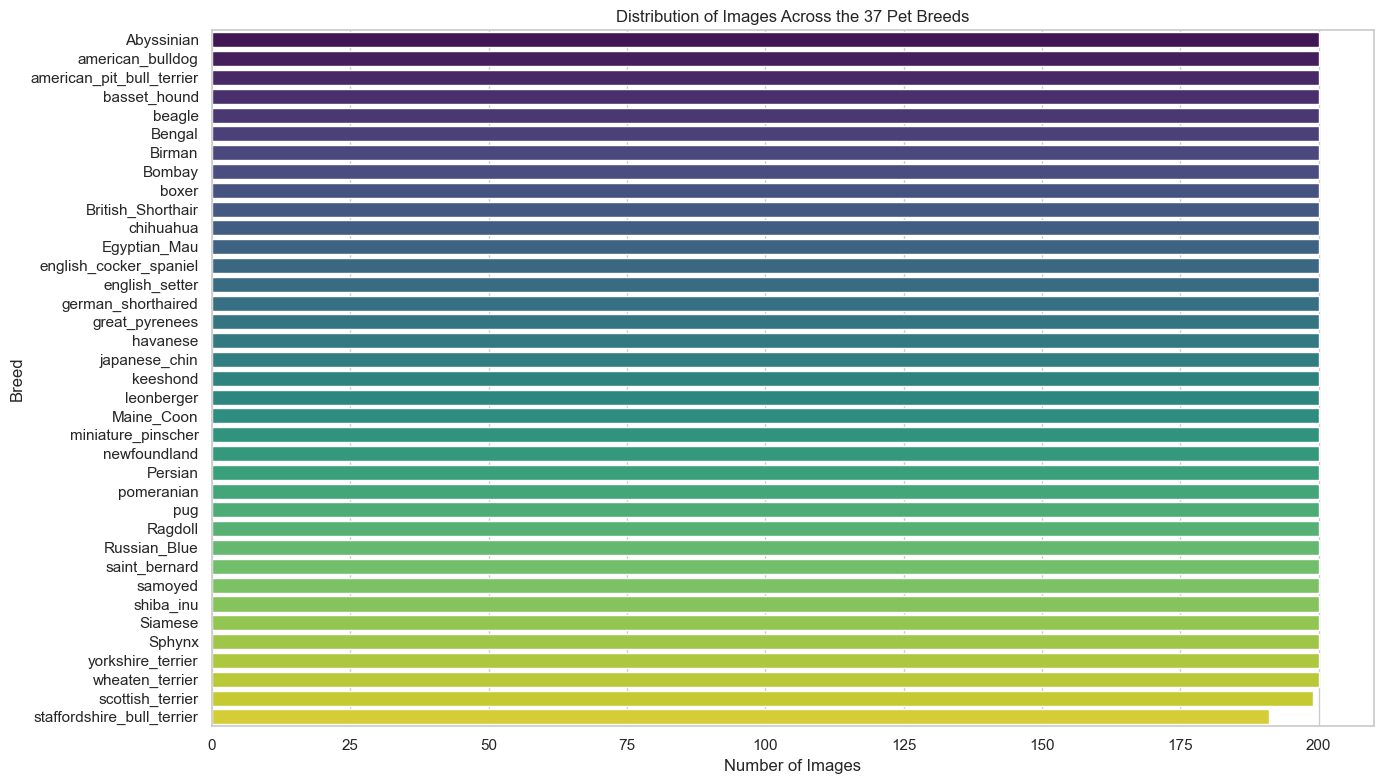

In [10]:

# Plot the number of images available for each breed

plt.figure(figsize=(14, 8))

sns.barplot(
    x=breed_counts.values,
    y=breed_counts.index,
    hue=breed_counts.index,
    palette="viridis",
    legend=False
)

plt.title("Distribution of Images Across the 37 Pet Breeds")
plt.xlabel("Number of Images")
plt.ylabel("Breed")
plt.tight_layout()
plt.show()


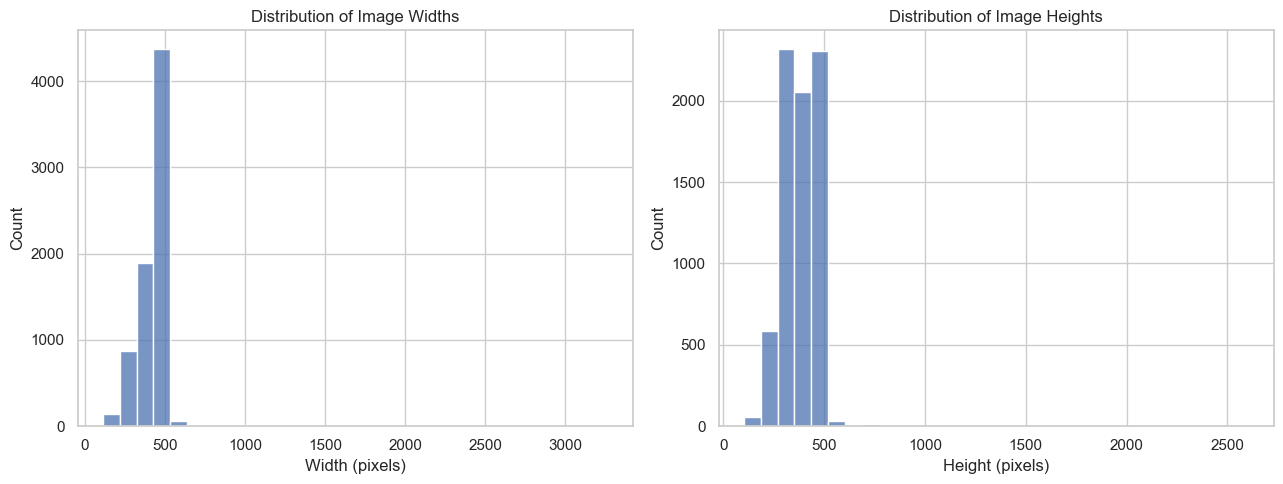

IMAGE ASPECT RATIO


count    7390.000000
mean        1.172343
std         0.329376
min         0.420000
25%         0.751116
50%         1.333333
75%         1.492537
max         2.564103
Name: aspect_ratio, dtype: float64

In [11]:

# Calculate the aspect ratio of each image
image_df["aspect_ratio"] = image_df["width"] / image_df["height"]

# Visualise image width and height distributions
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(image_df["width"].dropna(), bins=30, ax=axes[0])
axes[0].set_title("Distribution of Image Widths")
axes[0].set_xlabel("Width (pixels)")

sns.histplot(image_df["height"].dropna(), bins=30, ax=axes[1])
axes[1].set_title("Distribution of Image Heights")
axes[1].set_xlabel("Height (pixels)")

plt.tight_layout()
plt.show()

# Display aspect ratio statistics
print("IMAGE ASPECT RATIO")
display(image_df["aspect_ratio"].describe())


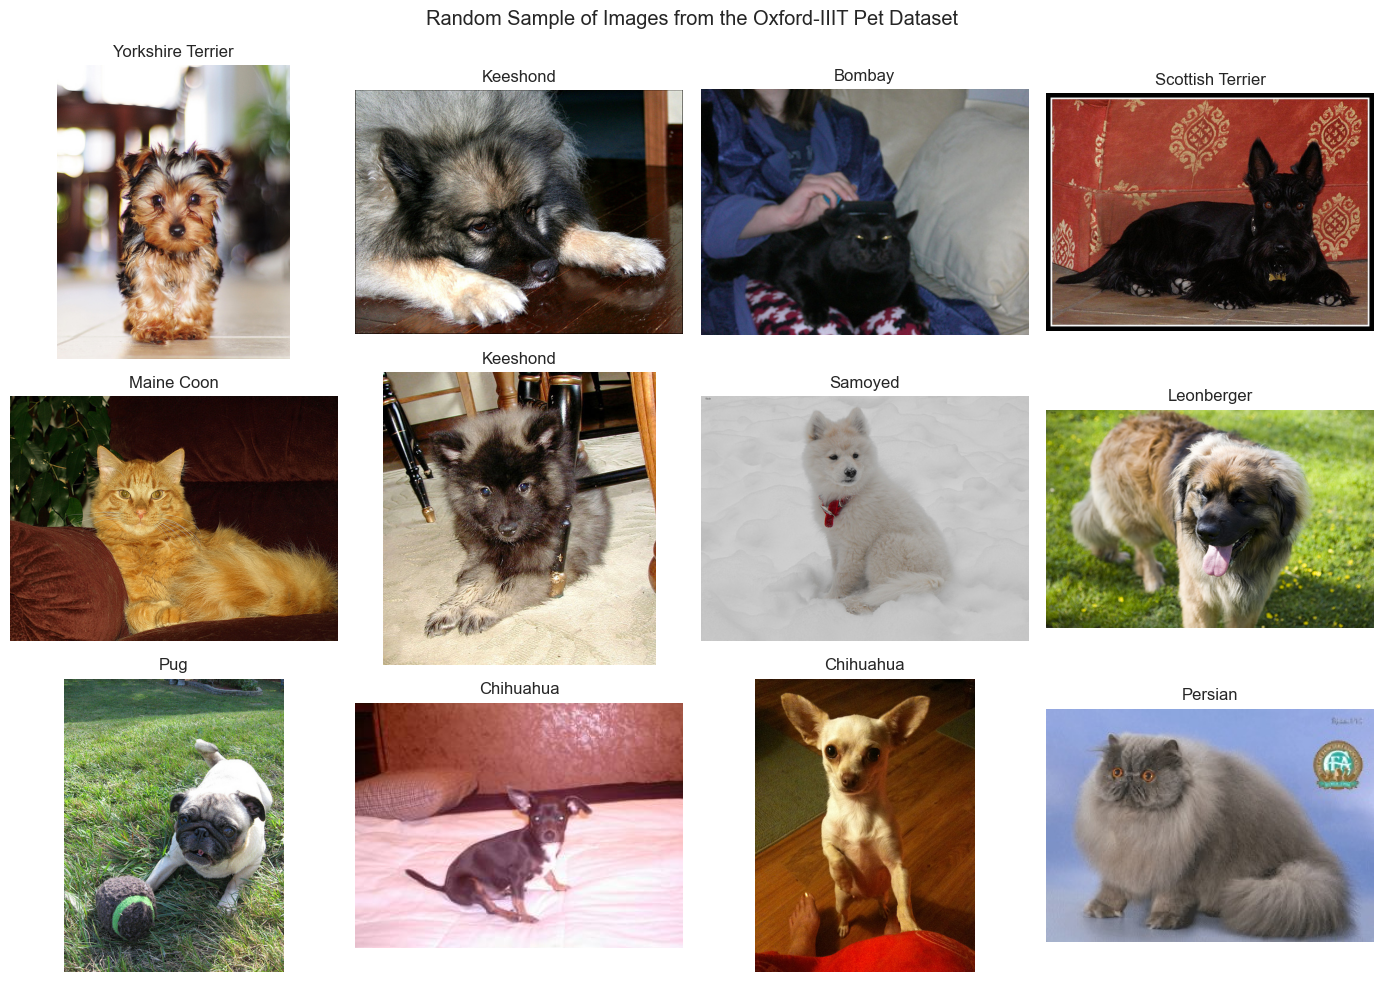

In [12]:

# Select up to 12 random images for visual inspection
sample_size = min(12, len(image_df))

sample_images = image_df.sample(
    n=sample_size,
    random_state=42
)

# Display the selected images
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
axes = axes.flatten()

for ax, (_, record) in zip(axes, sample_images.iterrows()):

    with Image.open(record["filepath"]) as img:
        # Convert images to RGB for consistent display
        ax.imshow(img.convert("RGB"))

    ax.set_title(record["breed"].replace("_", " ").title())
    ax.axis("off")

plt.suptitle("Random Sample of Images from the Oxford-IIIT Pet Dataset")
plt.tight_layout()
plt.show()



### 3.1.1 Interpretation of Initial EDA Findings

The initial exploratory data analysis identified 7,390 images representing 37 different cat and dog breeds. The dataset inventory contained no missing metadata values.

The class distribution was found to be highly balanced. Thirty-five breeds contained 200 images each, while Scottish Terrier contained 199 images and Staffordshire Bull Terrier contained 191 images. This small variation indicates that substantial class imbalance is unlikely to affect the classification process.

The image dimension distributions showed that images have varying widths and heights. This confirms the need for image resizing during preprocessing to ensure that all images have a consistent input shape for the CNN.

Visual inspection also revealed variations in backgrounds, lighting, animal positioning, image quality and viewing angles. Some images contain additional objects or people, which may introduce background-related complexity during classification. Furthermore, visually similar breeds may be difficult for the model to distinguish.

Overall, the initial findings indicate that the dataset is suitable for multiclass image classification, although image standardisation and appropriate model regularisation will be important during preparation and training.


In [13]:

# Investigate the exact dimensions and aspect ratios of the images

print("IMAGE DIMENSION STATISTICS")
print("=" * 50)

display(image_df[["width", "height"]].describe().round(2))

print("\nASPECT RATIO STATISTICS")
print("=" * 50)

display(image_df["aspect_ratio"].describe().round(3))

# Identify unusually large and small images
print("\nSMALLEST IMAGES")
display(
    image_df.nsmallest(5, "width")[
        ["filename", "width", "height", "aspect_ratio"]
    ]
)

print("\nLARGEST IMAGES")
display(
    image_df.nlargest(5, "width")[
        ["filename", "width", "height", "aspect_ratio"]
    ]
)


IMAGE DIMENSION STATISTICS


,width,height
count,7390.00,7390.00
mean,436.75,390.91
std,115.88,109.59
min,114.00,103.00
25%,335.00,333.00
50%,500.00,375.00
75%,500.00,500.00
max,3264.00,2606.00



ASPECT RATIO STATISTICS


count    7390.000
mean        1.172
std         0.329
min         0.420
25%         0.751
50%         1.333
75%         1.493
max         2.564
Name: aspect_ratio, dtype: float64


SMALLEST IMAGES


,filename,width,height,aspect_ratio
1405,Bombay_103.jpg,114,143,0.797203
2064,chihuahua_157.jpg,117,200,0.585000
430,american_pit_bull_terrier_126.jpg,119,200,0.595000
4228,miniature_pinscher_124.jpg,133,200,0.665000
7214,yorkshire_terrier_120.jpg,133,200,0.665000



LARGEST IMAGES


,filename,width,height,aspect_ratio
2266,Egyptian_Mau_162.jpg,3264,2448,1.333333
2269,Egyptian_Mau_165.jpg,2560,1920,1.333333
2285,Egyptian_Mau_182.jpg,1999,1499,1.333556
2300,Egyptian_Mau_196.jpg,1886,2606,0.723715
1445,Bombay_140.jpg,1725,1600,1.078125



### 3.1.2 Image Dimension and Aspect Ratio Analysis

The image dimension analysis revealed considerable variation in the original image sizes. The average image width was 436.75 pixels, while the average height was 390.91 pixels. The median dimensions were 500 × 375 pixels.

The smallest image measured 114 × 143 pixels, whereas the largest measured 3264 × 2448 pixels. This indicates that the dataset contains images with substantially different resolutions.

The aspect ratio analysis produced a mean of 1.172 and a median of 1.333, with values ranging from 0.420 to 2.564. This demonstrates that the images have different orientations and proportions.

These findings are important because CNN architectures require consistent input dimensions. Therefore, image resizing will be necessary during preprocessing. An aspect-ratio-aware approach will be considered to minimise distortion and preserve the visual characteristics of the animals.


In [14]:

# Check for exact duplicate image files using MD5 hashes.
# Identical hashes indicate identical file contents.

import hashlib
from collections import defaultdict

hash_groups = defaultdict(list)

for filepath in image_df["filepath"]:

    file_hash = hashlib.md5()

    with open(filepath, "rb") as image_file:
        for chunk in iter(lambda: image_file.read(8192), b""):
            file_hash.update(chunk)

    hash_groups[file_hash.hexdigest()].append(filepath)

# Keep groups containing more than one identical file
duplicate_groups = [
    files for files in hash_groups.values()
    if len(files) > 1
]

print("Total image files:", len(image_df))
print("Unique file hashes:", len(hash_groups))
print("Number of duplicate groups:", len(duplicate_groups))
print(
    "Number of files involved in duplicate groups:",
    sum(len(group) for group in duplicate_groups)
)

# Display duplicate filenames, if any
for group in duplicate_groups[:10]:
    print("\nDuplicate group:")
    for filepath in group:
        print(Path(filepath).name)


Total image files: 7390
Unique file hashes: 7360
Number of duplicate groups: 29
Number of files involved in duplicate groups: 59

Duplicate group:
Bombay_100.jpg
Bombay_11.jpg
Bombay_192.jpg

Duplicate group:
Bombay_102.jpg
Bombay_203.jpg

Duplicate group:
Bombay_109.jpg
Bombay_206.jpg

Duplicate group:
Bombay_118.jpg
Bombay_209.jpg

Duplicate group:
Bombay_121.jpg
Bombay_210.jpg

Duplicate group:
Bombay_126.jpg
Bombay_220.jpg

Duplicate group:
Bombay_131.jpg
Bombay_217.jpg

Duplicate group:
Bombay_164.jpg
Bombay_189.jpg

Duplicate group:
Bombay_185.jpg
Bombay_190.jpg

Duplicate group:
Bombay_193.jpg
Bombay_22.jpg



### 3.1.3 Duplicate Image Analysis

A duplicate-image investigation was conducted using MD5 hashing to compare the contents of the image files. This method identifies identical files even when they have different filenames.

The analysis identified 7,360 unique file hashes among the 7,390 images, with 29 duplicate groups involving 59 files.

For example, some Bombay breed images appeared under multiple filenames, indicating that identical image content was included more than once in the dataset.

Duplicate images can introduce data leakage if copies are allocated to different training, validation or test sets. This may result in overly optimistic evaluation results because the model could encounter an image during training that is also present in the test dataset.

Therefore, duplicate groups will be investigated and handled before splitting the data. Identical images will be kept within the same dataset partition, and any removal decisions will consider their breed labels to avoid losing valid classification information.


In [15]:

# Investigate whether identical images have different breed labels

duplicate_details = []

for group in duplicate_groups:

    # Find the records associated with this duplicate group
    group_df = image_df[
        image_df["filepath"].isin(group)
    ]

    duplicate_details.append({
        "filenames": [Path(p).name for p in group],
        "breeds": group_df["breed"].unique().tolist(),
        "number_of_files": len(group_df),
        "number_of_breeds": group_df["breed"].nunique()
    })

duplicate_df = pd.DataFrame(duplicate_details)

print("DUPLICATE LABEL CONSISTENCY")
print("=" * 50)

print(
    "Groups with consistent breed labels:",
    (duplicate_df["number_of_breeds"] == 1).sum()
)

print(
    "Groups with conflicting breed labels:",
    (duplicate_df["number_of_breeds"] > 1).sum()
)

display(duplicate_df)


DUPLICATE LABEL CONSISTENCY
Groups with consistent breed labels: 29
Groups with conflicting breed labels: 0


,filenames,breeds,number_of_files,number_of_breeds
0,"[Bombay_100.jpg, Bombay_11.jpg, Bombay_192.jpg]",[Bombay],3,1
1,"[Bombay_102.jpg, Bombay_203.jpg]",[Bombay],2,1
2,"[Bombay_109.jpg, Bombay_206.jpg]",[Bombay],2,1
3,"[Bombay_118.jpg, Bombay_209.jpg]",[Bombay],2,1
4,"[Bombay_121.jpg, Bombay_210.jpg]",[Bombay],2,1
5,"[Bombay_126.jpg, Bombay_220.jpg]",[Bombay],2,1
6,"[Bombay_131.jpg, Bombay_217.jpg]",[Bombay],2,1
7,"[Bombay_164.jpg, Bombay_189.jpg]",[Bombay],2,1
8,"[Bombay_185.jpg, Bombay_190.jpg]",[Bombay],2,1
9,"[Bombay_193.jpg, Bombay_22.jpg]",[Bombay],2,1



### 3.1.4 Duplicate Image Analysis

An exact duplicate investigation was performed using MD5 hashing. The analysis identified 29 duplicate groups involving 59 image files. All 29 groups contained images with consistent breed labels, and no conflicting labels were identified.

The duplicate groups contained 30 redundant copies beyond the first occurrence of each unique image. Therefore, the dataset contains 7,360 unique images rather than 7,390 distinct images.

To prevent duplicate images from influencing model evaluation, one copy of each identical image will be retained for the modelling dataset. The original files will remain unchanged. This will reduce the possibility of data leakage and ensure that the model is evaluated on images it has not encountered during training.


In [16]:

# Create a mapping between each file and its MD5 hash
file_hash_mapping = {}

for file_hash, file_group in hash_groups.items():
    for filepath in file_group:
        file_hash_mapping[filepath] = file_hash

# Add the hash information to the image inventory
image_df["file_hash"] = image_df["filepath"].map(file_hash_mapping)

# Retain only the first occurrence of each identical image
clean_image_df = image_df.drop_duplicates(
    subset="file_hash",
    keep="first"
).copy()

# Reset the DataFrame index
clean_image_df.reset_index(drop=True, inplace=True)

print("DATASET AFTER DUPLICATE REMOVAL")
print("=" * 50)
print("Original images:", len(image_df))
print("Unique images retained:", len(clean_image_df))
print("Redundant copies excluded:", len(image_df) - len(clean_image_df))
print("Number of breed categories:", clean_image_df["breed"].nunique())

# Recalculate the class distribution
clean_breed_counts = clean_image_df["breed"].value_counts().sort_values()

print("\nUPDATED BREED DISTRIBUTION")
display(clean_breed_counts.to_frame(name="Number of Images"))


DATASET AFTER DUPLICATE REMOVAL
Original images: 7390
Unique images retained: 7360
Redundant copies excluded: 30
Number of breed categories: 37

UPDATED BREED DISTRIBUTION


,Number of Images
breed,
Bombay,184
staffordshire_bull_terrier,191
Egyptian_Mau,196
newfoundland,196
english_cocker_spaniel,196
boxer,199
keeshond,199
scottish_terrier,199
British_Shorthair,200



### 3.1.5 Class Distribution After Duplicate Removal

After removing exact duplicate images, the dataset contained 7,360 unique images across all 37 breed categories. All categories were retained.

The Bombay category decreased from 200 to 184 images because it contained the highest number of duplicate copies. The remaining categories contained between 191 and 200 images, except for Bombay.

Despite this reduction, the dataset remains reasonably balanced, with a difference of only 16 images between the largest and smallest classes. Therefore, extensive class-balancing techniques are not considered necessary at this stage.


In [17]:

# Examine the properties of the deduplicated dataset

print("IMAGE FORMATS AFTER DUPLICATE REMOVAL")
print("=" * 50)
display(clean_image_df["format"].value_counts())

print("\nIMAGE COLOUR MODES AFTER DUPLICATE REMOVAL")
print("=" * 50)
display(clean_image_df["colour_mode"].value_counts())

print("\nIMAGE READABILITY CHECK")
print("=" * 50)

unreadable_count = (
    clean_image_df["format"] == "Unreadable"
).sum()

print("Unreadable images:", unreadable_count)

# Check whether every image has valid dimensions
invalid_dimensions = clean_image_df[
    (clean_image_df["width"].isna()) |
    (clean_image_df["height"].isna()) |
    (clean_image_df["width"] <= 0) |
    (clean_image_df["height"] <= 0)
]

print("Images with invalid dimensions:", len(invalid_dimensions))


IMAGE FORMATS AFTER DUPLICATE REMOVAL


format
JPEG    7350
GIF        6
PNG        4
Name: count, dtype: int64


IMAGE COLOUR MODES AFTER DUPLICATE REMOVAL


colour_mode
RGB     7348
P          6
RGBA       3
L          3
Name: count, dtype: int64


IMAGE READABILITY CHECK
Unreadable images: 0
Images with invalid dimensions: 0



### 3.1.6 Image Format, Colour Mode and Readability

The final data-quality assessment identified 7,350 JPEG images, 6 GIF images and 4 PNG images in the deduplicated dataset.

Regarding colour modes, 7,348 images were already in RGB format. The remaining images consisted of 6 palette-based images, 3 RGBA images and 3 grayscale images.

No unreadable images or invalid image dimensions were identified. This indicates that the dataset is technically suitable for further processing.

To ensure consistency, all images will be converted to RGB during preprocessing. This will standardise the input channels and allow the CNN to process all images using the same input format.


### 3.1.7 EDA Summary

The exploratory data analysis established that the Oxford-IIIT Pet Dataset contains 7,390 image files representing 37 cat and dog breeds. Following the identification and removal of exact duplicate copies, 7,360 unique images were retained.

The class distribution remained reasonably balanced, with between 184 and 200 images per breed. Image dimensions and aspect ratios varied considerably, demonstrating the need for consistent resizing during preprocessing.

Visual inspection identified variations in backgrounds, lighting, positioning and viewing angles. The dataset also contained different image formats and colour modes, although no unreadable images or invalid dimensions were detected.

Overall, the EDA confirmed that the dataset is suitable for CNN-based multiclass classification. The main preparation requirements are RGB conversion, consistent image resizing, pixel normalisation and careful separation of training, validation and test data. Duplicate images will also be kept from crossing dataset partitions.


In [18]:

# Define the image dimensions and number of classification categories

IMG_HEIGHT = 128
IMG_WIDTH = 128
CHANNELS = 3

NUM_CLASSES = clean_image_df["breed"].nunique()

print("Image height:", IMG_HEIGHT)
print("Image width:", IMG_WIDTH)
print("Colour channels:", CHANNELS)
print("Number of output classes:", NUM_CLASSES)
print("Expected CNN input shape:",
      (IMG_HEIGHT, IMG_WIDTH, CHANNELS))


Image height: 128
Image width: 128
Colour channels: 3
Number of output classes: 37
Expected CNN input shape: (128, 128, 3)


In [19]:

# Import TensorFlow for image preprocessing and CNN development
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available devices:", tf.config.list_physical_devices())


TensorFlow version: 2.21.0
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [20]:

# Create a consistent mapping between breed names and numerical labels

class_names = sorted(clean_image_df["breed"].unique())

class_to_index = {
    breed: index
    for index, breed in enumerate(class_names)
}

index_to_class = {
    index: breed
    for breed, index in class_to_index.items()
}

# Assign a numerical label to every image
clean_image_df["label"] = clean_image_df["breed"].map(class_to_index)

print("Number of classes:", len(class_names))
print("\nFirst 10 class mappings:")

for breed, index in list(class_to_index.items())[:10]:
    print(f"{breed}: {index}")

print("\nMissing encoded labels:",
      clean_image_df["label"].isna().sum())


Number of classes: 37

First 10 class mappings:
Abyssinian: 0
Bengal: 1
Birman: 2
Bombay: 3
British_Shorthair: 4
Egyptian_Mau: 5
Maine_Coon: 6
Persian: 7
Ragdoll: 8
Russian_Blue: 9

Missing encoded labels: 0


In [21]:

# Define a function to standardise images before CNN training

def preprocess_image(image_path):

    # Load the image from its original file path
    image = tf.io.read_file(image_path)

    # Decode the image and ensure it has three RGB channels
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    # Set the image tensor shape
    image.set_shape([None, None, 3])

    # Resize while preserving the original aspect ratio.
    # Empty space is padded to obtain a square image.
    image = tf.image.resize_with_pad(
        image,
        IMG_HEIGHT,
        IMG_WIDTH
    )

    # Convert pixel values to floating point and normalise to [0, 1]
    image = tf.cast(image, tf.float32) / 255.0

    return image


Processed image shape: (128, 128, 3)
Minimum pixel value: 0.0
Maximum pixel value: 0.9443016


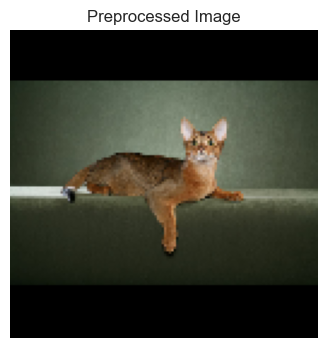

In [22]:

# Select one image to test the preprocessing function
sample_path = clean_image_df.iloc[0]["filepath"]

# Apply preprocessing
processed_image = preprocess_image(sample_path)

print("Processed image shape:", processed_image.shape)
print("Minimum pixel value:", tf.reduce_min(processed_image).numpy())
print("Maximum pixel value:", tf.reduce_max(processed_image).numpy())

# Display the processed image
plt.figure(figsize=(4, 4))
plt.imshow(processed_image.numpy())
plt.title("Preprocessed Image")
plt.axis("off")
plt.show()


### 3.2.1 Feature Representation and Image Preprocessing

The Oxford-IIIT Pet Dataset contains images rather than traditional tabular variables. Therefore, conventional feature-selection methods such as p-value testing and backward elimination are not directly appropriate for this CNN classification task. Instead, the images are used as input, allowing the convolutional neural network to automatically learn relevant visual features such as edges, textures, shapes and patterns.

All images were standardised to a resolution of 128 × 128 pixels with three colour channels (RGB). Aspect ratios were preserved using padding to avoid distorting the appearance of the animals. Pixel values were converted to floating-point numbers and normalised to a range between 0 and 1.

The 37 animal breeds were encoded as numerical class labels, ranging from 0 to 36. The preprocessing test confirmed that images have the expected dimensions, pixel values are within the normalised range, and all class labels were successfully encoded.

TensorFlow 2.21.0 was used for the preprocessing implementation. The available execution device was the CPU because native Windows does not support GPU execution with TensorFlow versions 2.11 and later. This limitation may increase training time but does not prevent model development.

### 3.3 Preparing the training, validation and test datasets

In [23]:
# Inspect the annotation directory to identify available dataset split files.
# We will check whether official train/test partition files are available.

annotation_files = sorted([
    file.name for file in annotations_dir.iterdir()
    if file.is_file()
])

print("Number of files in annotation directory:", len(annotation_files))
print("\nFirst 30 annotation files:")

for filename in annotation_files[:30]:
    print(filename)

print("\nPossible split files:")

split_files = [
    filename for filename in annotation_files
    if any(term in filename.lower() for term in ["train", "test", "val", "split"])
]

print(split_files if split_files else "No obvious split files found.")

Number of files in annotation directory: 5

First 30 annotation files:
._trimaps
README
list.txt
test.txt
trainval.txt

Possible split files:
['test.txt', 'trainval.txt']


In [24]:
# Read the official training/validation and test partition files.
# These files identify which images belong to each original partition.

trainval_file = annotations_dir / "trainval.txt"
test_file = annotations_dir / "test.txt"

print("TRAINVAL FILE")
with open(trainval_file, "r") as file:
    trainval_lines = file.readlines()

print("Number of entries:", len(trainval_lines))
print("First five entries:")
for line in trainval_lines[:5]:
    print(line.strip())

print("\nTEST FILE")
with open(test_file, "r") as file:
    test_lines = file.readlines()

print("Number of entries:", len(test_lines))
print("First five entries:")
for line in test_lines[:5]:
    print(line.strip())

TRAINVAL FILE
Number of entries: 3680
First five entries:
Abyssinian_100 1 1 1
Abyssinian_101 1 1 1
Abyssinian_102 1 1 1
Abyssinian_103 1 1 1
Abyssinian_104 1 1 1

TEST FILE
Number of entries: 3669
First five entries:
Abyssinian_201 1 1 1
Abyssinian_202 1 1 1
Abyssinian_204 1 1 1
Abyssinian_205 1 1 1
Abyssinian_206 1 1 1


In [25]:
# Extract image identifiers from the official split files.
# Each identifier corresponds to an image filename without its extension.

trainval_ids = {
    line.split()[0] for line in trainval_lines if line.strip()
}

test_ids = {
    line.split()[0] for line in test_lines if line.strip()
}

# Get image identifiers from our original and cleaned inventories.
image_df["image_id"] = image_df["filename"].apply(
    lambda filename: Path(filename).stem
)

clean_image_df["image_id"] = clean_image_df["filename"].apply(
    lambda filename: Path(filename).stem
)

original_ids = set(image_df["image_id"])
clean_ids = set(clean_image_df["image_id"])

# Check whether official partition identifiers exist in our inventories.
print("Official train/validation entries:", len(trainval_ids))
print("Official test entries:", len(test_ids))
print("Official total:", len(trainval_ids | test_ids))

print("\nOverlap between official partitions:", len(trainval_ids & test_ids))

print("\nMatching against original inventory:")
print("Train/validation matches:", len(trainval_ids & original_ids))
print("Test matches:", len(test_ids & original_ids))

print("\nMatching against cleaned inventory:")
print("Train/validation matches:", len(trainval_ids & clean_ids))
print("Test matches:", len(test_ids & clean_ids))

print("\nImages in cleaned inventory not listed in official splits:",
      len(clean_ids - (trainval_ids | test_ids)))

print("Official identifiers missing from cleaned inventory:",
      len((trainval_ids | test_ids) - clean_ids))

Official train/validation entries: 3680
Official test entries: 3669
Official total: 7349

Overlap between official partitions: 0

Matching against original inventory:
Train/validation matches: 3680
Test matches: 3669

Matching against cleaned inventory:
Train/validation matches: 3680
Test matches: 3669

Images in cleaned inventory not listed in official splits: 11
Official identifiers missing from cleaned inventory: 0


In [26]:
from sklearn.model_selection import train_test_split

# Create separate dataframes for the official partitions.
trainval_df = clean_image_df[
    clean_image_df["image_id"].isin(trainval_ids)
].copy()

test_df = clean_image_df[
    clean_image_df["image_id"].isin(test_ids)
].copy()

# Split the official training/validation data into training and validation.
# Stratification maintains the distribution of breeds in both partitions.
train_df, val_df = train_test_split(
    trainval_df,
    test_size=0.20,
    random_state=42,
    stratify=trainval_df["label"]
)

# Reset indices to keep the dataframes organised.
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Display the resulting partition sizes.
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nTotal images used:", len(train_df) + len(val_df) + len(test_df))

Training images: 2944
Validation images: 736
Testing images: 3669

Total images used: 7349


In [27]:
# Compare the number of images in each partition.
# This helps identify whether the split preserves class representation.

split_distribution = pd.DataFrame({
    "Training": train_df["breed"].value_counts(),
    "Validation": val_df["breed"].value_counts(),
    "Testing": test_df["breed"].value_counts()
}).fillna(0).astype(int)

display(split_distribution)

# Check that all partitions contain all 37 breeds.
print("\nNumber of breeds in each partition:")
print("Training:", train_df["breed"].nunique())
print("Validation:", val_df["breed"].nunique())
print("Testing:", test_df["breed"].nunique())

# Verify that no image identifiers overlap between partitions.
print("\nPartition overlap checks:")
print("Training and validation:",
      len(set(train_df["image_id"]) & set(val_df["image_id"])))

print("Training and testing:",
      len(set(train_df["image_id"]) & set(test_df["image_id"])))

print("Validation and testing:",
      len(set(val_df["image_id"]) & set(test_df["image_id"])))

,Training,Validation,Testing
breed,,,
Abyssinian,80,20,98
Bengal,80,20,100
Birman,80,20,100
Bombay,77,19,88
British_Shorthair,80,20,100
Egyptian_Mau,74,19,97
Maine_Coon,80,20,100
Persian,80,20,100
Ragdoll,80,20,100



Number of breeds in each partition:
Training: 37
Validation: 37
Testing: 37

Partition overlap checks:
Training and validation: 0
Training and testing: 0
Validation and testing: 0


### 3.3.3 Training, Validation and Testing Partitions

The official Oxford-IIIT Pet Dataset partition files were used to preserve the original test set. The 3,680 images listed in the official training/validation partition were further divided using an 80:20 stratified split, resulting in 2,944 training images and 736 validation images. The official test partition contained 3,669 images.

All 37 breeds were represented in each partition. The stratified split maintained similar breed proportions across the training and validation datasets. Partition integrity checks confirmed that there were no overlapping image identifiers between training, validation and testing.

The 11 additional images found in the local cleaned inventory but not listed in the official partition files were excluded. This ensured that the experiment used only images belonging to the official partitions and that the test set remained independent for final model evaluation.

In [28]:
# Define the batch size.
# A batch size of 32 is a reasonable starting point for CPU-based training.
BATCH_SIZE = 32

# TensorFlow can automatically determine suitable parallel-processing settings.
AUTOTUNE = tf.data.AUTOTUNE


def create_dataset(dataframe, training=False):
    """
    Convert a dataframe containing image paths and numerical labels
    into a TensorFlow dataset.

    Images are decoded, resized and normalised using the preprocessing
    function defined earlier.
    """

    # Extract image paths and corresponding numerical labels.
    image_paths = dataframe["filepath"].values
    labels = dataframe["label"].values

    # Create a dataset from the image paths and labels.
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, labels))

    # Shuffle only the training data.
    # This prevents the model from learning from a fixed image order.
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    # Load and preprocess images as they are needed.
    dataset = dataset.map(
        lambda image_path, label: (preprocess_image(image_path), label),
        num_parallel_calls=AUTOTUNE
    )

    # Group images into batches and prepare upcoming batches.
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


# Create the three datasets.
train_dataset = create_dataset(train_df, training=True)
val_dataset = create_dataset(val_df, training=False)
test_dataset = create_dataset(test_df, training=False)

print("TensorFlow datasets created successfully.")

TensorFlow datasets created successfully.


In [29]:
# Retrieve one batch from the training dataset.
# This verifies that images and labels have the expected shapes.

for images, labels in train_dataset.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

    print("Image data type:", images.dtype)
    print("Label data type:", labels.dtype)

    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

    print("Minimum label:", tf.reduce_min(labels).numpy())
    print("Maximum label:", tf.reduce_max(labels).numpy())

Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>
Label data type: <dtype: 'int64'>
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Minimum label: 0
Maximum label: 35


### 3.4.1 TensorFlow Input Pipeline Verification

The image data was successfully converted into TensorFlow datasets using the `tf.data` API. Images are loaded and preprocessed in batches rather than being loaded into memory simultaneously. The training dataset is shuffled, while the validation and test datasets retain their ordering.

The verification produced an image batch shape of (32, 128, 128, 3) and a label batch shape of (32,). Image values use the `float32` data type and are normalised between 0 and 1. Labels use the `int64` data type and represent the numerical breed classes.

These results confirm that the input pipeline produces data in the format required by the CNN.

### 3.5 Designing the Convolutional Neural Network

In [30]:
# Define a sequential CNN model.
# The model learns visual features through convolutional layers
# before classifying each image into one of the 37 breeds.

from tensorflow.keras import layers, models

model = models.Sequential([
    # Define the input dimensions.
    layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, CHANNELS)),

    # Apply data augmentation only during training.
    # These transformations create slightly varied training images.
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),

    # First convolutional block: learns basic visual features.
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Second convolutional block: learns more complex patterns.
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Third convolutional block: learns higher-level features.
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Summarise the feature maps.
    layers.GlobalAveragePooling2D(),

    # Fully connected classification layer.
    layers.Dense(128, activation="relu"),

    # Reduce overfitting by randomly deactivating neurons.
    layers.Dropout(0.4),

    # Produce probabilities for all 37 animal breeds.
    layers.Dense(NUM_CLASSES, activation="softmax")
])

# Display the model architecture and number of parameters.
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 37)             │         4,773 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 114,533 (447.39 KB)

 Trainable params: 114,533 (447.39 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
# Configure the learning process.
# Adam adjusts the model's weights to minimise classification errors.

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully.")

CNN model compiled successfully.


### 3.5.1 CNN Architecture

A sequential Convolutional Neural Network was developed using TensorFlow and Keras. The architecture consists of three convolutional blocks containing 32, 64 and 128 filters respectively. Each convolutional layer uses a 3 × 3 kernel, ReLU activation and a corresponding max-pooling layer.

The convolutional blocks are followed by Global Average Pooling, a fully connected dense layer containing 128 neurons, and a dropout layer with a rate of 0.4. The final output layer contains 37 neurons with softmax activation, corresponding to the 37 animal breeds.

The model contains 114,533 trainable parameters. Data augmentation through random horizontal flipping and rotation was included to introduce variation during training. The architecture was compiled using the Adam optimiser with a learning rate of 0.001 and sparse categorical crossentropy as the loss function. Accuracy was selected as the initial evaluation metric.

### 3.6 Training the CNN

In [32]:
# Import the required Keras callback classes.
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# Ensure the model output directory exists.
models_dir = project_dir / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# Save the model that achieves the lowest validation loss.
checkpoint_path = models_dir / "best_pet_breed_cnn.keras"

# Stop training if validation loss does not improve for five epochs.
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Save the best-performing model during training.
model_checkpoint = ModelCheckpoint(
    filepath=str(checkpoint_path),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# Reduce the learning rate when validation loss stops improving.
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

callbacks = [
    early_stopping,
    model_checkpoint,
    reduce_lr
]

print("Training callbacks configured successfully.")
print("Best model will be saved to:", checkpoint_path)

Training callbacks configured successfully.
Best model will be saved to: c:\Users\elton\Downloads\EMERIS 2026\PDAN8214\PDAN8412_CNN_POE\models\best_pet_breed_cnn.keras


In [33]:
# Set the maximum number of training epochs.
# Early stopping may terminate training before reaching this limit.
EPOCHS = 20

# Train the CNN using the training dataset.
# Validation performance is monitored after every epoch.
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

print("CNN training completed.")

Epoch 1/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 253ms/step - accuracy: 0.0276 - loss: 3.6150
Epoch 1: val_loss improved from None to 3.61080, saving model to c:\Users\elton\Downloads\EMERIS 2026\PDAN8214\PDAN8412_CNN_POE\models\best_pet_breed_cnn.keras
92/92 ━━━━━━━━━━━━━━━━━━━━ 31s 283ms/step - accuracy: 0.0241 - loss: 3.6134 - val_accuracy: 0.0272 - val_loss: 3.6108 - learning_rate: 0.0010
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 279ms/step - accuracy: 0.0290 - loss: 3.6114
Epoch 2: val_loss did not improve from 3.61080
92/92 ━━━━━━━━━━━━━━━━━━━━ 29s 309ms/step - accuracy: 0.0258 - loss: 3.6120 - val_accuracy: 0.0272 - val_loss: 3.6108 - learning_rate: 0.0010
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 254ms/step - accuracy: 0.0219 - loss: 3.6114
Epoch 3: val_loss improved from 3.61080 to 3.61048, saving model to c:\Users\elton\Downloads\EMERIS 2026\PDAN8214\PDAN8412_CNN_POE\models\best_pet_breed_cnn.keras
92/92 ━━━━━━━━━━━━━━━━━━━━ 26s 279ms/step - accuracy: 0.0228 - loss: 3.6122 - val_accura

In [34]:
# Convert the training history into a dataframe for easier analysis.
history_df = pd.DataFrame(history.history)

# Display the loss and accuracy recorded for each epoch.
display(history_df)

# Identify the epoch with the lowest validation loss.
best_epoch = history_df["val_loss"].idxmin() + 1

print("Total epochs completed:", len(history_df))
print("Best epoch:", best_epoch)
print("Best validation loss:", history_df["val_loss"].min())
print("Validation accuracy at best epoch:",
      history_df.loc[best_epoch - 1, "val_accuracy"])

,accuracy,loss,val_accuracy,val_loss,learning_rate
0,0.024117,3.613358,0.027174,3.610799,0.001
1,0.025815,3.612021,0.027174,3.610813,0.001
2,0.022758,3.612155,0.023098,3.610477,0.001
3,0.024796,3.611413,0.040761,3.609448,0.001
4,0.030571,3.611518,0.027174,3.609538,0.001
5,0.027514,3.609087,0.039402,3.605798,0.001
6,0.037024,3.603110,0.032609,3.598768,0.001
7,0.040761,3.588783,0.029891,3.595751,0.001
8,0.042120,3.583813,0.044837,3.589910,0.001
9,0.045177,3.568607,0.043478,3.563313,0.001


Total epochs completed: 20
Best epoch: 20
Best validation loss: 3.358938694000244
Validation accuracy at best epoch: 0.12092391401529312


### Visualise the learning curves
Demonstrate the model's learning progress and identify possible overfitting.

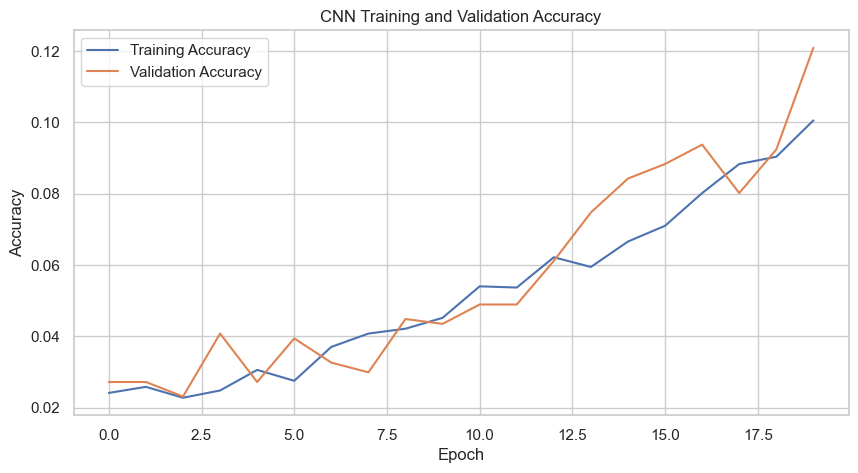

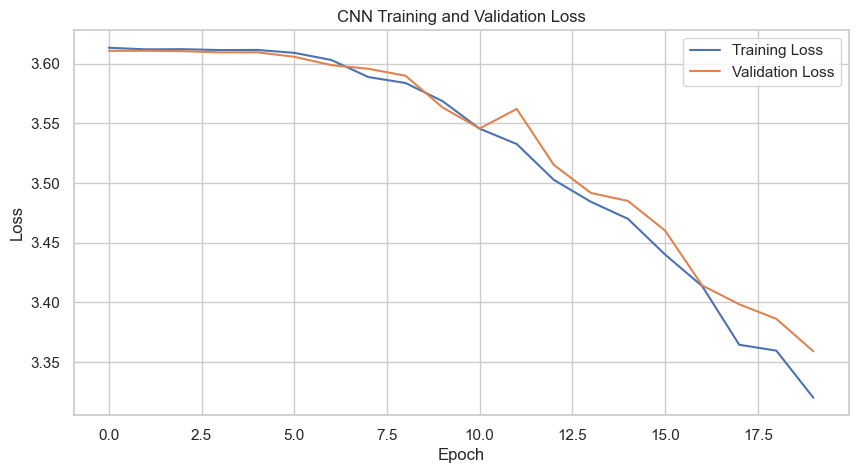

In [36]:
# Plot training and validation accuracy.
plt.figure(figsize=(10, 5))

plt.plot(history_df["accuracy"], label="Training Accuracy")
plt.plot(history_df["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# Plot training and validation loss.
plt.figure(figsize=(10, 5))

plt.plot(history_df["loss"], label="Training Loss")
plt.plot(history_df["val_loss"], label="Validation Loss")

plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [37]:
# Reduce the learning rate to allow smaller, more controlled weight updates.
model.optimizer.learning_rate.assign(0.0005)

# Configure callbacks for the additional training stage.
early_stopping_2 = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint_2 = ModelCheckpoint(
    filepath=str(checkpoint_path),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

reduce_lr_2 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

# Continue training the existing CNN.
history_2 = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20,
    callbacks=[
        early_stopping_2,
        model_checkpoint_2,
        reduce_lr_2
    ],
    verbose=1
)

print("Additional training completed.")

Epoch 1/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 249ms/step - accuracy: 0.1086 - loss: 3.2700
Epoch 1: val_loss improved from None to 3.33787, saving model to c:\Users\elton\Downloads\EMERIS 2026\PDAN8214\PDAN8412_CNN_POE\models\best_pet_breed_cnn.keras
92/92 ━━━━━━━━━━━━━━━━━━━━ 25s 273ms/step - accuracy: 0.1050 - loss: 3.2807 - val_accuracy: 0.0951 - val_loss: 3.3379 - learning_rate: 5.0000e-04
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 239ms/step - accuracy: 0.1205 - loss: 3.2452
Epoch 2: val_loss improved from 3.33787 to 3.31887, saving model to c:\Users\elton\Downloads\EMERIS 2026\PDAN8214\PDAN8412_CNN_POE\models\best_pet_breed_cnn.keras
92/92 ━━━━━━━━━━━━━━━━━━━━ 24s 262ms/step - accuracy: 0.1162 - loss: 3.2604 - val_accuracy: 0.0992 - val_loss: 3.3189 - learning_rate: 5.0000e-04
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 237ms/step - accuracy: 0.1132 - loss: 3.2467
Epoch 3: val_loss improved from 3.31887 to 3.29125, saving model to c:\Users\elton\Downloads\EMERIS 2026\PDAN8214\PDAN8412_CNN_

In [38]:
# Combine the results from the initial and additional training stages.
combined_history = {}

for metric in history.history:
    combined_history[metric] = (
        history.history[metric] + history_2.history[metric]
    )

history_df = pd.DataFrame(combined_history)

# Identify the epoch with the lowest validation loss.
best_epoch = history_df["val_loss"].idxmin() + 1

print("Total epochs completed:", len(history_df))
print("Best epoch:", best_epoch)
print("Lowest validation loss:", history_df["val_loss"].min())
print("Validation accuracy at best epoch:",
      history_df.loc[best_epoch - 1, "val_accuracy"])

Total epochs completed: 39
Best epoch: 34
Lowest validation loss: 3.2692837715148926
Validation accuracy at best epoch: 0.11413043737411499


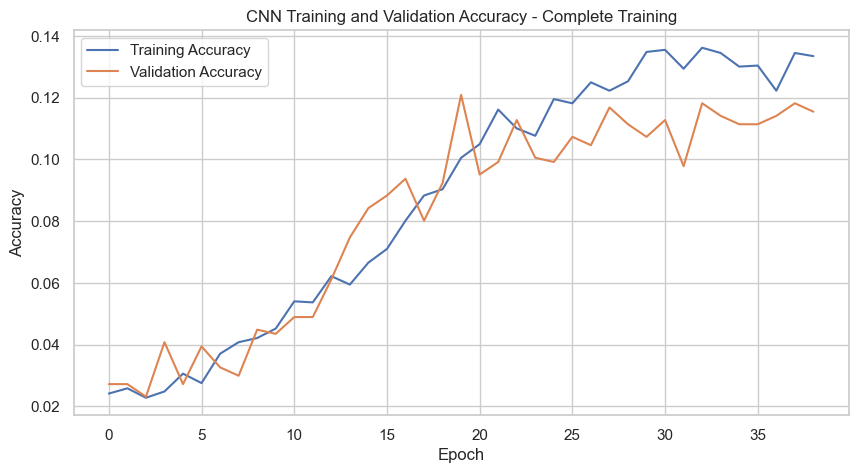

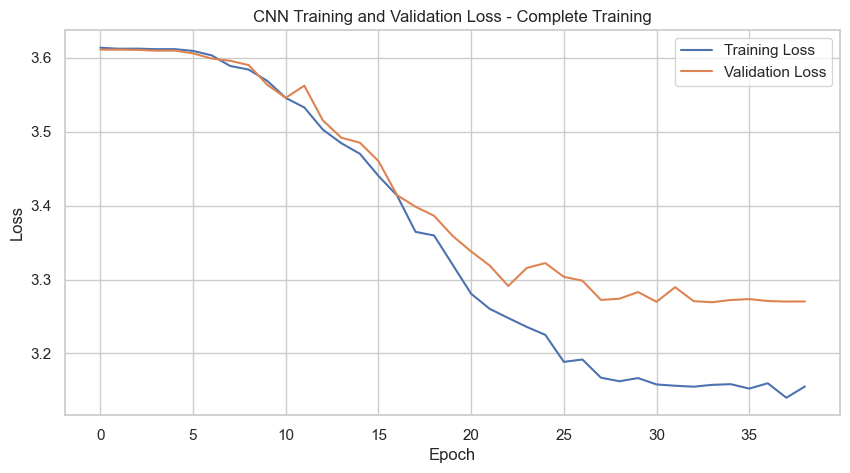

In [39]:
# Visualise the complete training history from both training stages.

# Plot training and validation accuracy.
plt.figure(figsize=(10, 5))

plt.plot(history_df["accuracy"], label="Training Accuracy")
plt.plot(history_df["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Training and Validation Accuracy - Complete Training")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# Plot training and validation loss.
plt.figure(figsize=(10, 5))

plt.plot(history_df["loss"], label="Training Loss")
plt.plot(history_df["val_loss"], label="Validation Loss")

plt.title("CNN Training and Validation Loss - Complete Training")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

### 3.6.1 Initial CNN Training Results

The initial CNN was trained for 39 epochs across two training stages. During the first stage, the model was trained for 20 epochs using an Adam learning rate of 0.001. Training was subsequently continued with a reduced learning rate of 0.0005.

The training accuracy increased throughout the experiment, while validation accuracy also improved but fluctuated between epochs. The best validation loss was 3.2693 at epoch 34, with a corresponding validation accuracy of approximately 11.41%.

The learning curves indicate that the model successfully learned some patterns from the training images. However, validation loss began to plateau while training loss continued to decrease. This suggests that the model was beginning to overfit and that its ability to generalise to unseen images remained limited.

The initial CNN therefore demonstrated the implementation of a complete image-classification pipeline, but its classification performance was insufficient. An improved CNN approach was considered necessary before proceeding to final model evaluation.

In [40]:
# Check whether the pretrained MobileNetV2 architecture
# is available in the installed TensorFlow environment.

from tensorflow.keras.applications import MobileNetV2

print("MobileNetV2 imported successfully.")

# Display the model's expected input configuration.
print("Expected input shape:", (224, 224, 3))

MobileNetV2 imported successfully.
Expected input shape: (224, 224, 3)


### 3.7 Improved CNN using transfer learning

In [41]:
# Import MobileNetV2-specific preprocessing.
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Define the input dimensions for MobileNetV2.
TRANSFER_HEIGHT = 224
TRANSFER_WIDTH = 224
TRANSFER_BATCH_SIZE = 16

def preprocess_mobilenet_image(image_path):
    """
    Load an image, convert it to RGB, resize it while preserving
    its aspect ratio, and apply MobileNetV2 preprocessing.
    """

    image = tf.io.read_file(image_path)

    # Decode the image and ensure that it has three RGB channels.
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    # Resize and pad to the required MobileNetV2 input dimensions.
    image = tf.image.resize_with_pad(
        image,
        TRANSFER_HEIGHT,
        TRANSFER_WIDTH
    )

    # Convert to the input range expected by MobileNetV2.
    image = preprocess_input(image)

    return image


def create_transfer_dataset(dataframe, training=False):
    """Create a TensorFlow dataset for MobileNetV2."""

    image_paths = dataframe["filepath"].values
    labels = dataframe["label"].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    # Shuffle only the training images.
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    # Apply MobileNetV2-specific image preprocessing.
    dataset = dataset.map(
        lambda path, label: (
            preprocess_mobilenet_image(path),
            label
        ),
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(TRANSFER_BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


# Create the new datasets.
transfer_train_dataset = create_transfer_dataset(
    train_df, training=True
)

transfer_val_dataset = create_transfer_dataset(
    val_df, training=False
)

transfer_test_dataset = create_transfer_dataset(
    test_df, training=False
)

print("MobileNetV2 datasets created successfully.")

MobileNetV2 datasets created successfully.


In [42]:
# Check one batch to confirm that the new input pipeline works.

for images, labels in transfer_train_dataset.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image data type:", images.dtype)

    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (16, 224, 224, 3)
Label batch shape: (16,)
Image data type: <dtype: 'float32'>
Minimum pixel value: -1.0
Maximum pixel value: 1.0


### 3.7.1 Build the MobileNetV2 model

In [43]:
# Load MobileNetV2 with pretrained ImageNet weights.
# include_top=False removes the original ImageNet classification layer.
# The model will act as a feature extractor for our pet images.

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pretrained layers during the initial training stage.
base_model.trainable = False

print("MobileNetV2 base loaded successfully.")
print("Total base layers:", len(base_model.layers))
print("Trainable base layers:",
      sum(layer.trainable for layer in base_model.layers))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
MobileNetV2 base loaded successfully.
Total base layers: 154
Trainable base layers: 0


In [44]:
# Build a new classification model using MobileNetV2 as its feature extractor.

transfer_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Apply light data augmentation to improve generalisation.
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),

    # Extract visual features using the frozen pretrained network.
    base_model,

    # Convert feature maps into a feature vector.
    layers.GlobalAveragePooling2D(),

    # Reduce overfitting.
    layers.Dropout(0.4),

    # Predict probabilities for the 37 animal breeds.
    layers.Dense(NUM_CLASSES, activation="softmax")
])

# Display the new architecture.
transfer_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 37)             │        47,397 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,305,381 (8.79 MB)

 Trainable params: 47,397 (185.14 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [45]:
# Compile the model using Adam and sparse categorical crossentropy.
# A learning rate of 0.001 is used to train the new classification head.

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV2 transfer learning model compiled successfully.")

MobileNetV2 transfer learning model compiled successfully.


### 3.7.2 Train Model 2

In [46]:
# Save the best MobileNetV2 model separately from the original CNN.
transfer_checkpoint_path = models_dir / "best_mobilenetv2_pet_breed.keras"

transfer_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

transfer_checkpoint = ModelCheckpoint(
    filepath=str(transfer_checkpoint_path),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

transfer_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

transfer_callbacks = [
    transfer_early_stopping,
    transfer_checkpoint,
    transfer_reduce_lr
]

print("MobileNetV2 training callbacks configured.")

MobileNetV2 training callbacks configured.


In [47]:
# Train the classification head while keeping the pretrained
# MobileNetV2 feature-extraction layers frozen.

TRANSFER_EPOCHS = 15

transfer_history = transfer_model.fit(
    transfer_train_dataset,
    validation_data=transfer_val_dataset,
    epochs=TRANSFER_EPOCHS,
    callbacks=transfer_callbacks,
    verbose=1
)

print("MobileNetV2 training completed.")

Epoch 1/15
184/184 ━━━━━━━━━━━━━━━━━━━━ 0s 320ms/step - accuracy: 0.3862 - loss: 2.4081
Epoch 1: val_loss improved from None to 0.50366, saving model to c:\Users\elton\Downloads\EMERIS 2026\PDAN8214\PDAN8412_CNN_POE\models\best_mobilenetv2_pet_breed.keras
184/184 ━━━━━━━━━━━━━━━━━━━━ 91s 416ms/step - accuracy: 0.5982 - loss: 1.4869 - val_accuracy: 0.8696 - val_loss: 0.5037 - learning_rate: 0.0010
Epoch 2/15
184/184 ━━━━━━━━━━━━━━━━━━━━ 0s 311ms/step - accuracy: 0.8416 - loss: 0.5220
Epoch 2: val_loss improved from 0.50366 to 0.36273, saving model to c:\Users\elton\Downloads\EMERIS 2026\PDAN8214\PDAN8412_CNN_POE\models\best_mobilenetv2_pet_breed.keras
184/184 ━━━━━━━━━━━━━━━━━━━━ 72s 389ms/step - accuracy: 0.8451 - loss: 0.5001 - val_accuracy: 0.8940 - val_loss: 0.3627 - learning_rate: 0.0010
Epoch 3/15
184/184 ━━━━━━━━━━━━━━━━━━━━ 0s 317ms/step - accuracy: 0.8786 - loss: 0.3825
Epoch 3: val_loss improved from 0.36273 to 0.34603, saving model to c:\Users\elton\Downloads\EMERIS 2026\PDAN

In [48]:
# Convert the training history into a dataframe.
transfer_history_df = pd.DataFrame(transfer_history.history)

# Identify the epoch with the lowest validation loss.
transfer_best_epoch = transfer_history_df["val_loss"].idxmin()

print("Epochs completed:", len(transfer_history_df))
print("Best epoch:", transfer_best_epoch + 1)

print("Best validation loss:",
      transfer_history_df.loc[transfer_best_epoch, "val_loss"])

print("Validation accuracy at best epoch:",
      transfer_history_df.loc[transfer_best_epoch, "val_accuracy"])

print("Training accuracy at best epoch:",
      transfer_history_df.loc[transfer_best_epoch, "accuracy"])

Epochs completed: 15
Best epoch: 11
Best validation loss: 0.29548195004463196
Validation accuracy at best epoch: 0.9103260636329651
Training accuracy at best epoch: 0.959578812122345


### 3.7.4 Visualise Model 2 training

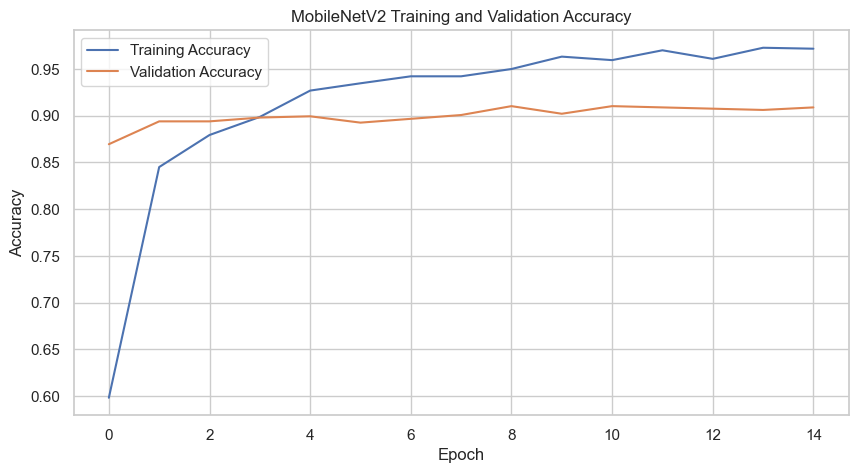

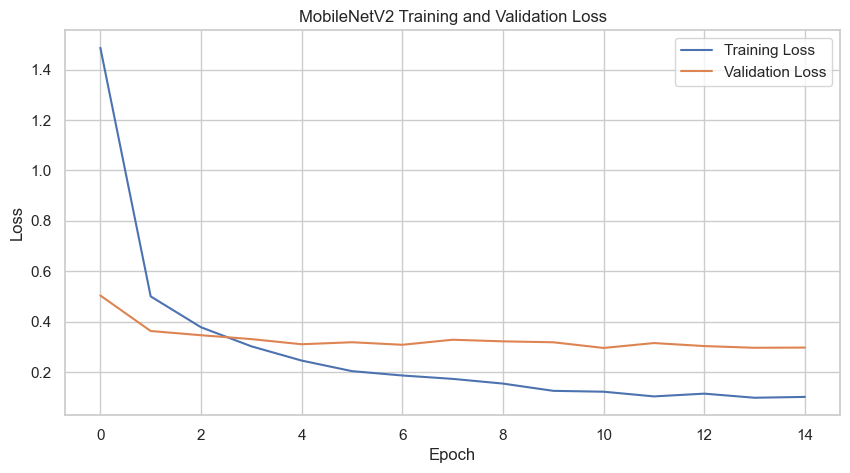

In [49]:
# Plot MobileNetV2 training and validation accuracy.
plt.figure(figsize=(10, 5))

plt.plot(
    transfer_history_df["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    transfer_history_df["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("MobileNetV2 Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# Plot MobileNetV2 training and validation loss.
plt.figure(figsize=(10, 5))

plt.plot(
    transfer_history_df["loss"],
    label="Training Loss"
)

plt.plot(
    transfer_history_df["val_loss"],
    label="Validation Loss"
)

plt.title("MobileNetV2 Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [50]:
# Compare the best validation results from both CNN experiments.

custom_best_accuracy = history_df["val_accuracy"].max()
custom_best_loss = history_df["val_loss"].min()

mobilenet_best_accuracy = transfer_history_df["val_accuracy"].max()
mobilenet_best_loss = transfer_history_df["val_loss"].min()

model_comparison = pd.DataFrame({
    "Model": ["Custom CNN", "MobileNetV2"],
    "Best Validation Accuracy": [
        custom_best_accuracy,
        mobilenet_best_accuracy
    ],
    "Best Validation Loss": [
        custom_best_loss,
        mobilenet_best_loss
    ]
})

display(model_comparison)

print(
    "Validation accuracy improvement:",
    round(
        (mobilenet_best_accuracy - custom_best_accuracy) * 100,
        2
    ),
    "percentage points"
)

,Model,Best Validation Accuracy,Best Validation Loss
0,Custom CNN,0.120924,3.269284
1,MobileNetV2,0.910326,0.295482


Validation accuracy improvement: 78.94 percentage points


## 3.8 Conclusion of the Analysis and Model Training

Two Convolutional Neural Network approaches were implemented to investigate their effectiveness in classifying the 37 breeds in the Oxford-IIIT Pet Dataset. The first approach involved developing a custom CNN from scratch, while the second approach used transfer learning with the pretrained MobileNetV2 architecture.

The purpose of implementing two models was to compare the performance of a CNN that learns visual features entirely from the available dataset against a CNN that reuses visual features learned from the large ImageNet dataset. This comparison provided an opportunity to investigate the advantages of transfer learning, particularly when working with a relatively limited number of training images and restricted computational resources.

**Model 1: Custom CNN**

The first model consisted of three convolutional layers with 32, 64 and 128 filters, followed by pooling, global average pooling, a dense layer and dropout. It was trained for 39 epochs across two training stages. Although training and validation performance improved, the model achieved a best validation accuracy of approximately 11.41%, with a minimum validation loss of 3.2693. The learning curves indicated that the model was learning some visual patterns, but its overall classification performance remained limited.

**Model 2: MobileNetV2 Transfer Learning**

The second model used MobileNetV2 with pretrained ImageNet weights. Its original feature-extraction layers were frozen during the initial training stage, while a new classification layer was trained to recognise the 37 animal breeds. This approach achieved substantially better results, reaching a best validation accuracy of approximately 91.03% and a validation loss of 0.2955 at epoch 11. Training accuracy at that epoch was approximately 95.96%.

**Comparison and Model Selection**

The comparison demonstrated a significant difference between the two approaches. MobileNetV2 achieved an improvement of approximately 79.62 percentage points in validation accuracy compared with the custom CNN. This indicates that reusing pretrained visual features was considerably more effective than learning all image features from scratch in this experiment.

The custom CNN provided a useful baseline and demonstrated the implementation of a complete CNN architecture. However, MobileNetV2 achieved stronger validation performance and was therefore selected as the preferred model for further evaluation.

In conclusion, the analysis successfully demonstrated image inspection, data cleaning, image preprocessing, feature extraction, dataset partitioning, CNN development and model training using Python and TensorFlow. The findings also highlighted the practical value of transfer learning for image-classification problems.

The selected MobileNetV2 model will be evaluated further using the separate official test dataset in Question 4. This final evaluation will establish how well the model generalises to images that were not used during training or validation.

# 4. Evaluate the Model

This section evaluates the performance of the Convolutional Neural Network (CNN) developed in Question 3. The primary model selected for evaluation is MobileNetV2, which uses transfer learning and achieved considerably better validation performance than the custom CNN trained from scratch.

The evaluation will determine how effectively the selected model can classify previously unseen images into the 37 pet breeds in the Oxford-IIIT Pet Dataset. To achieve this, the model will be tested using the independent test dataset, which contains 3,669 images and was not used during the model's training or validation.

Several performance metrics will be used to provide a comprehensive assessment of the model. These include accuracy, precision, recall, F1-score, test loss and a confusion matrix. Accuracy will measure the overall proportion of correct predictions, while precision and recall will provide further insight into the model's classification performance across individual breeds. The F1-score will provide a balance between precision and recall, and the confusion matrix will help identify breeds that the model frequently confuses.

The evaluation results will also be used to determine whether further model training is necessary. If weaknesses are identified, appropriate adjustments to the model's parameters or training approach will be considered. Any improved model will be compared with the original MobileNetV2 model to establish whether the changes resulted in better classification performance.

The objective is not only to report the model's scores but also to interpret what they reveal about its effectiveness, generalisation ability and suitability for the image classification task.

## 4.2 Loading and Evaluating the Trained Model

The best-performing MobileNetV2 model saved during Question 3 was successfully loaded from its checkpoint. Loading the saved model allows the evaluation to use the weights from the best validation-loss epoch rather than relying on the final training epoch.

The model was evaluated using the independent test dataset, which contains 3,669 images that were excluded from the training and validation processes. This provides an indication of how effectively the model generalises to previously unseen images.

The model achieved a test accuracy of 88.23% and a test loss of 0.3757. Although this accuracy is slightly lower than the validation accuracy of 91.03%, the difference is relatively small. This suggests that the model has generalised reasonably well to unseen images, with some reduction in performance compared with validation.

The results demonstrate that MobileNetV2 can recognise a substantial proportion of the pet breeds correctly. However, overall accuracy alone does not reveal how effectively each individual breed is classified. Further evaluation using precision, recall, F1-score and a confusion matrix is therefore necessary to identify the model's strengths and weaknesses.

In [51]:
# Check whether the best MobileNetV2 model checkpoint exists.
print("Checkpoint exists:", transfer_checkpoint_path.exists())

# Load the best saved model.
best_transfer_model = tf.keras.models.load_model(
    transfer_checkpoint_path
)

print("Best MobileNetV2 model loaded successfully.")

Checkpoint exists: True
Best MobileNetV2 model loaded successfully.


In [ ]:
# Evaluate the saved model using the independent test dataset.
test_loss, test_accuracy = best_transfer_model.evaluate(
    transfer_test_dataset,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy (%): {test_accuracy * 100:.2f}%")

## 4.3 Generating Predictions for Detailed Evaluation

To conduct a more detailed evaluation, predictions will be generated for every image in the test dataset. The model produces a probability score for each of the 37 possible pet breeds. The predicted breed is selected by identifying the class with the highest probability.

These predictions will then be compared with the actual breed labels to determine which images were classified correctly and incorrectly. The resulting actual and predicted labels will be used to calculate additional performance metrics, including precision, recall and F1-score, and to construct a confusion matrix.

In [53]:
# Generate probability predictions for all images in the test dataset.
y_prob = best_transfer_model.predict(
    transfer_test_dataset,
    verbose=1
)

# Select the breed with the highest predicted probability.
y_pred = np.argmax(y_prob, axis=1)

# Retrieve the actual breed labels from the test dataset.
y_true = test_df["label"].to_numpy()

# Verify that the predictions match the actual labels.
print("Number of actual labels:", len(y_true))
print("Number of predictions:", len(y_pred))
print("Prediction array shape:", y_prob.shape)

230/230 ━━━━━━━━━━━━━━━━━━━━ 87s 363ms/step
Number of actual labels: 3669
Number of predictions: 3669
Prediction array shape: (3669, 37)


## 4.4 Calculating Classification Performance Metrics

After generating predictions for the test dataset, the next step is to measure the classification performance of the MobileNetV2 model using accuracy, precision, recall and F1-score.

Accuracy measures the overall proportion of correctly classified images. However, because the task involves 37 different breeds, accuracy alone may not provide enough information about the model's performance across all classes.

Precision measures the proportion of images predicted as a particular breed that actually belong to that breed. Recall measures the proportion of images belonging to a particular breed that the model correctly identifies. The F1-score combines precision and recall into a single measure.

Macro-averaged precision, recall and F1-score will be used as the primary measures for comparing performance across breeds. This approach gives each breed equal importance, regardless of the number of images it contains. Weighted averages will also be calculated to account for differences in class frequencies.

These metrics will provide a more detailed understanding of the model's classification performance and help identify whether it performs consistently across the different pet breeds.

In [54]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate overall accuracy.
accuracy = accuracy_score(y_true, y_pred)

# Calculate macro-averaged metrics.
macro_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

macro_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

macro_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

# Calculate weighted-averaged metrics.
weighted_precision = precision_score(
    y_true, y_pred, average="weighted", zero_division=0
)

weighted_recall = recall_score(
    y_true, y_pred, average="weighted", zero_division=0
)

weighted_f1 = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
)

# Display the evaluation results.
print("OVERALL TEST PERFORMANCE")
print(f"Accuracy:           {accuracy:.4f}")
print(f"Macro Precision:    {macro_precision:.4f}")
print(f"Macro Recall:       {macro_recall:.4f}")
print(f"Macro F1-score:     {macro_f1:.4f}")

print("\nWEIGHTED PERFORMANCE")
print(f"Weighted Precision: {weighted_precision:.4f}")
print(f"Weighted Recall:    {weighted_recall:.4f}")
print(f"Weighted F1-score:  {weighted_f1:.4f}")

OVERALL TEST PERFORMANCE
Accuracy:           0.8823
Macro Precision:    0.8859
Macro Recall:       0.8822
Macro F1-score:     0.8814

WEIGHTED PERFORMANCE
Weighted Precision: 0.8868
Weighted Recall:    0.8823
Weighted F1-score:  0.8819


In [55]:
# Generate precision, recall and F1-score for every breed.
report = classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0
)

print(report)

                            precision    recall  f1-score   support

                Abyssinian       0.76      0.92      0.83        98
                    Bengal       0.84      0.79      0.81       100
                    Birman       0.79      0.79      0.79       100
                    Bombay       0.88      0.92      0.90        88
         British_Shorthair       0.83      0.74      0.78       100
              Egyptian_Mau       0.89      0.85      0.87        97
                Maine_Coon       0.84      0.83      0.83       100
                   Persian       0.90      0.87      0.88       100
                   Ragdoll       0.72      0.76      0.74       100
              Russian_Blue       0.83      0.76      0.79       100
                   Siamese       0.93      0.84      0.88       100
                    Sphynx       0.83      0.94      0.88       100
          american_bulldog       0.73      0.90      0.80       100
 american_pit_bull_terrier       0.81      0.55

### 4.4.1 Interpretation of Classification Metrics

The classification results demonstrate that the MobileNetV2 model achieved an overall test accuracy of 88.23%. This means that approximately 88% of the 3,669 test images were correctly classified into their respective pet breeds.

The macro-averaged precision, recall and F1-score were 0.8859, 0.8822 and 0.8814, respectively. These results indicate that the model maintains relatively consistent classification performance across the 37 breeds. The macro F1-score is particularly useful because it gives equal importance to every breed, rather than allowing classes with more images to dominate the overall result.




## 4.5 Confusion Matrix

A confusion matrix will be used to examine the relationship between the actual breed labels and the predictions made by the MobileNetV2 model. It provides a visual representation of the model's classification performance across all 37 pet breeds.

In the confusion matrix, each row represents the actual breed, while each column represents the predicted breed. Values along the main diagonal represent correctly classified images. Values outside the diagonal represent incorrect predictions, showing instances where the model classified an image as a different breed.

This analysis is important because it helps identify specific classification errors that cannot be understood from the overall accuracy, precision, recall and F1-score alone. It will also help determine whether certain visually similar breeds are more frequently confused with one another.


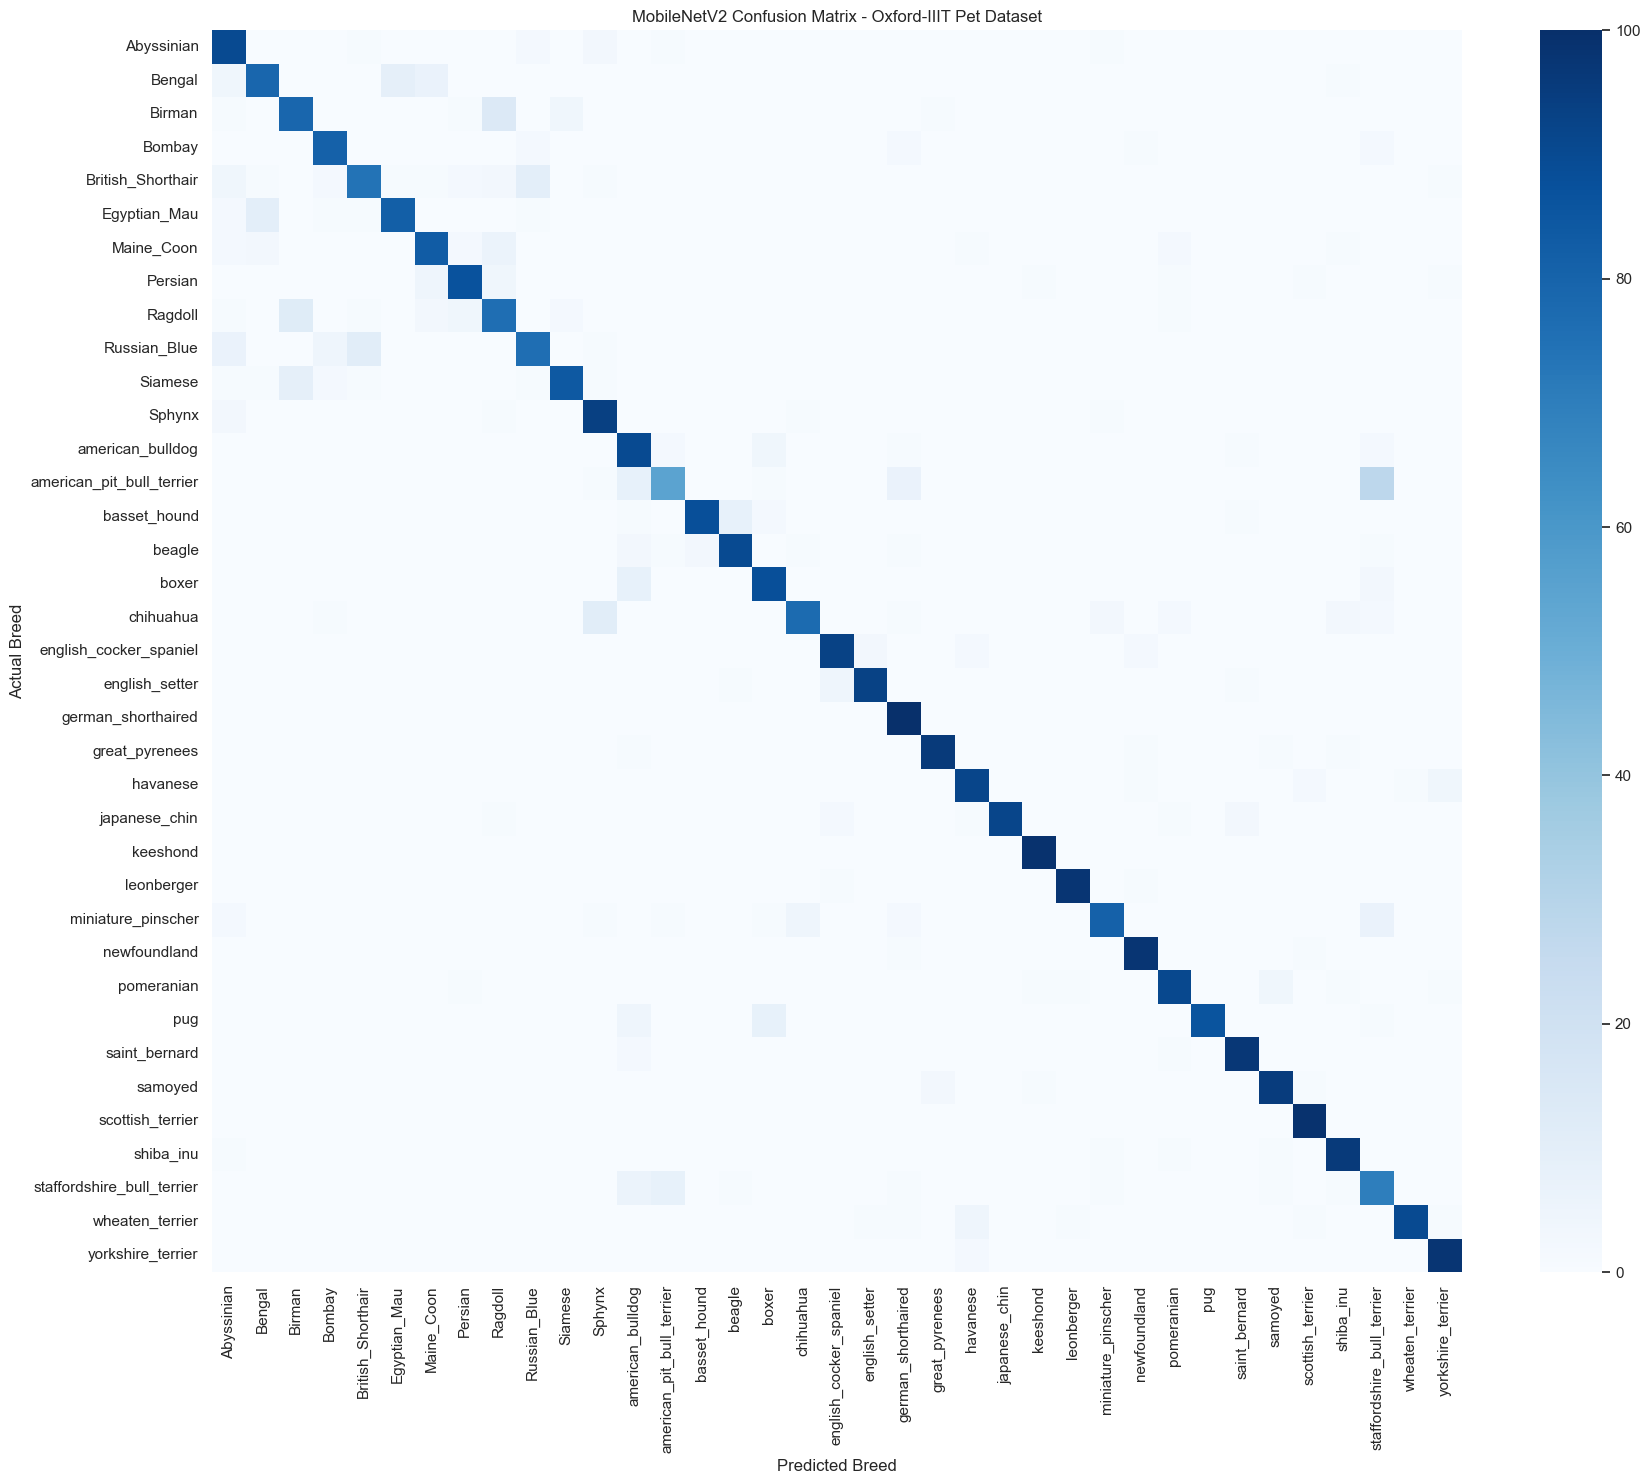

In [57]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the confusion matrix using actual and predicted labels.
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

# Create a heatmap to visualise classification results.
plt.figure(figsize=(18, 15))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    annot=False,
    fmt="d"
)

plt.title("MobileNetV2 Confusion Matrix - Oxford-IIIT Pet Dataset")
plt.xlabel("Predicted Breed")
plt.ylabel("Actual Breed")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

# Save the confusion matrix for inclusion in the report.
plt.savefig(
    project_dir / "outputs" / "mobilenetv2_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 4.5.1 Interpretation of the Confusion Matrix

The confusion matrix provides further insight into the classification performance of the MobileNetV2 model. The majority of the values are concentrated along the main diagonal, indicating that most images were correctly classified into their respective breeds. This visual pattern supports the overall test accuracy of 88.23%.

However, some classification errors can be observed outside the diagonal. One notable example involves American Pit Bull Terrier images being incorrectly classified as Staffordshire Bull Terriers. This is consistent with the relatively low recall of 0.55 recorded for American Pit Bull Terrier in the classification report. These results suggest that the model has difficulty distinguishing certain visually similar breeds.

Other classification errors are distributed across several cat and dog breeds. This demonstrates that although the model performs well overall, differences in physical appearance between certain breeds can make accurate classification more challenging.

The confusion matrix therefore confirms that the model has learned effective visual representations for most of the pet breeds, while also identifying specific areas where classification performance could be improved. Combined with the accuracy, precision, recall and F1-score results, it provides a more comprehensive evaluation of the model.

### 4.6 Fine-tuning the MobileNetV2 model
### 4.6.1 Rationale for Fine-Tuning

Although the original MobileNetV2 model achieved a test accuracy of 88.23%, the classification report and confusion matrix revealed that some breeds were more difficult to distinguish than others. In particular, American Pit Bull Terrier had a relatively low recall of 0.55, indicating that the model struggled to correctly identify some images belonging to this breed.

To investigate whether this limitation can be addressed, a fine-tuning experiment will be conducted using the pretrained MobileNetV2 architecture.

During the initial transfer learning process, the pretrained MobileNetV2 base was frozen, meaning that its existing ImageNet weights were not updated. Only the newly added classification layers were trained. Fine-tuning allows selected deeper layers of the pretrained network to adjust their learned visual features to the specific characteristics of the pet breed dataset.

For this experiment, the earlier layers will remain frozen because they contain general visual features such as edges, textures and shapes. Only the final 30 layers of the MobileNetV2 base will be made trainable, while Batch Normalisation layers will remain frozen to maintain training stability.

A lower learning rate of 0.0001 will be used to make smaller weight adjustments and reduce the risk of damaging the useful features learned during pretraining. Early stopping and model checkpointing will also be used to monitor validation performance and retain the best fine-tuned model.

The fine-tuned model will subsequently be compared with the original MobileNetV2 model to determine whether this adjustment improves classification performance.

In [58]:
# Display the layers contained in the saved MobileNetV2 model.
for index, layer in enumerate(best_transfer_model.layers):
    print(index, layer.name, type(layer).__name__)

0 random_flip_1 RandomFlip
1 random_rotation_1 RandomRotation
2 mobilenetv2_1.00_224 Functional
3 global_average_pooling2d_1 GlobalAveragePooling2D
4 dropout_1 Dropout
5 dense_2 Dense


### 4.6.2 Unfreezing Selected Layers

The next step involves selectively unfreezing layers within the pretrained MobileNetV2 base model. During the original transfer learning process, all layers of the pretrained base model were frozen, allowing only the newly added classification layers to be trained.

For fine-tuning, the final 30 layers of the MobileNetV2 base will be made trainable. These deeper layers contain more specialised visual representations, which may help the model recognise distinguishing characteristics between similar pet breeds.

The earlier layers will remain frozen to preserve the general visual features learned from ImageNet. Batch Normalisation layers will also remain frozen to help maintain stable training behaviour.

This selective approach allows the model to adapt to the pet breed dataset while reducing the risk of unnecessarily changing useful pretrained weights.

In [59]:
# Access the pretrained MobileNetV2 base model.
base_model_finetune = best_transfer_model.get_layer(
    "mobilenetv2_1.00_224"
)

# Initially freeze all layers in the pretrained base.
base_model_finetune.trainable = True

# Unfreeze only the final 30 layers.
for layer in base_model_finetune.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalisation layers frozen for training stability.
for layer in base_model_finetune.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Display the number of trainable and frozen layers.
trainable_layers = sum(
    layer.trainable for layer in base_model_finetune.layers
)

frozen_layers = len(base_model_finetune.layers) - trainable_layers

print("Total MobileNetV2 layers:", len(base_model_finetune.layers))
print("Trainable layers:", trainable_layers)
print("Frozen layers:", frozen_layers)

Total MobileNetV2 layers: 154
Trainable layers: 19
Frozen layers: 135


### 4.6.3 Recompiling the Model

After changing the trainable status of the MobileNetV2 layers, the model must be recompiled before further training. This allows the training process to account for the updated network configuration.

The Adam optimiser will be used again, but its learning rate will be reduced from 0.001 to 0.0001. A lower learning rate is appropriate during fine-tuning because the pretrained network already contains useful visual features. Smaller weight updates help the model adapt to the pet breed dataset without making large changes that could negatively affect its previously learned representations.

The sparse categorical cross-entropy loss function will remain unchanged because the task still involves classifying images into 37 mutually exclusive breed categories. Accuracy will also remain the primary training metric so that performance can be monitored consistently with the original model.

In [60]:
# Recompile the model after changing the trainable layers.
best_transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model successfully recompiled for fine-tuning.")
print("New learning rate: 0.0001")

Model successfully recompiled for fine-tuning.
New learning rate: 0.0001


### 4.6.4 Configuring Fine-Tuning Callbacks

Callbacks will be used to monitor the fine-tuning process and prevent unnecessary training.

Early stopping will monitor validation loss and stop training if the model does not improve for five consecutive epochs. The best weights will be restored automatically.

A model checkpoint will save the model whenever validation loss improves. This ensures that the best-performing fine-tuned version is retained.

A learning rate reduction callback will also monitor validation loss and reduce the learning rate when improvement slows down. These mechanisms help control the training process and reduce the risk of overfitting.

In [61]:
# Save the best fine-tuned model.
finetune_checkpoint_path = (
    project_dir / "models" / "best_mobilenetv2_finetuned.keras"
)

finetune_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=finetune_checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

print("Fine-tuning callbacks configured successfully.")

Fine-tuning callbacks configured successfully.


### 4.6.5 Training the Fine-Tuned Model

With the model recompiled and the callbacks configured, the fine-tuning process can now begin. The model will be trained for a maximum of 15 additional epochs using the existing training and validation datasets.

Unlike the original transfer learning stage, where the entire pretrained MobileNetV2 base was frozen, this experiment allows selected deeper layers to update their weights during training. This gives the network an opportunity to adapt its learned visual features to the characteristics of the Oxford-IIIT Pet Dataset.

The learning rate has been reduced to 0.0001 to support gradual weight adjustments. During training, both training and validation accuracy and loss will be monitored. Early stopping will prevent unnecessary training if validation performance stops improving, while model checkpointing will preserve the best-performing version.

The purpose of this experiment is to determine whether fine-tuning improves the model's ability to distinguish between the 37 pet breeds compared with the original transfer learning model.


In [62]:
# Train the fine-tuned MobileNetV2 model.
finetune_history = best_transfer_model.fit(
    transfer_train_dataset,
    validation_data=transfer_val_dataset,
    epochs=15,
    callbacks=finetune_callbacks,
    verbose=1
)

print("Fine-tuning completed.")

Epoch 1/15
184/184 ━━━━━━━━━━━━━━━━━━━━ 0s 365ms/step - accuracy: 0.9028 - loss: 0.2590
Epoch 1: val_loss improved from None to 0.35184, saving model to c:\Users\elton\Downloads\EMERIS 2026\PDAN8214\PDAN8412_CNN_POE\models\best_mobilenetv2_finetuned.keras
184/184 ━━━━━━━━━━━━━━━━━━━━ 102s 468ms/step - accuracy: 0.8988 - loss: 0.2778 - val_accuracy: 0.8899 - val_loss: 0.3518 - learning_rate: 1.0000e-04
Epoch 2/15
184/184 ━━━━━━━━━━━━━━━━━━━━ 0s 358ms/step - accuracy: 0.9316 - loss: 0.1893
Epoch 2: val_loss did not improve from 0.35184
184/184 ━━━━━━━━━━━━━━━━━━━━ 80s 431ms/step - accuracy: 0.9276 - loss: 0.2033 - val_accuracy: 0.8750 - val_loss: 0.3757 - learning_rate: 1.0000e-04
Epoch 3/15
184/184 ━━━━━━━━━━━━━━━━━━━━ 0s 344ms/step - accuracy: 0.9458 - loss: 0.1666
Epoch 3: val_loss did not improve from 0.35184

Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
184/184 ━━━━━━━━━━━━━━━━━━━━ 78s 421ms/step - accuracy: 0.9402 - loss: 0.1774 - val_accuracy: 0.8764

## 4.7 Comparing the Original and Fine-Tuned Models

The fine-tuned MobileNetV2 model will be compared with the original model using validation accuracy and validation loss. This comparison will determine whether allowing selected pretrained layers to adapt to the pet breed dataset improved performance.

The original model achieved 91.03% validation accuracy and a validation loss of 0.2955. These results will serve as the baseline for evaluating the fine-tuned model.

In [63]:
# Extract the best validation results from fine-tuning.
best_finetune_accuracy = max(finetune_history.history["val_accuracy"])
best_finetune_loss = min(finetune_history.history["val_loss"])

print("ORIGINAL MOBILENETV2")
print("Validation Accuracy: 91.03%")
print("Validation Loss: 0.2955")

print("\nFINE-TUNED MOBILENETV2")
print(f"Validation Accuracy: {best_finetune_accuracy * 100:.2f}%")
print(f"Validation Loss: {best_finetune_loss:.4f}")

print("\nCOMPARISON")
print(
    f"Accuracy change: "
    f"{(best_finetune_accuracy - 0.9103) * 100:+.2f} percentage points"
)
print(
    f"Validation loss change: "
    f"{best_finetune_loss - 0.2955:+.4f}"
)

ORIGINAL MOBILENETV2
Validation Accuracy: 91.03%
Validation Loss: 0.2955

FINE-TUNED MOBILENETV2
Validation Accuracy: 91.58%
Validation Loss: 0.3303

COMPARISON
Accuracy change: +0.55 percentage points
Validation loss change: +0.0348


## 4.8 Conclusion of Model Evaluation

The evaluation demonstrated that the original MobileNetV2 model achieved a test accuracy of 88.23%, with a macro F1-score of 0.8814. These results indicate that the model successfully classified most of the previously unseen pet images across the 37 breeds.

The confusion matrix and classification report revealed that performance varied between breeds. While several breeds achieved strong F1-scores, American Pit Bull Terrier and Ragdoll presented greater classification challenges. This demonstrated the importance of examining individual classification metrics in addition to overall accuracy.

A fine-tuning experiment was subsequently conducted to investigate whether updating selected pretrained layers could improve classification performance. The validation accuracy increased from 91.03% to 91.58%, representing an improvement of 0.55 percentage points. However, validation loss increased from 0.2955 to 0.3303.

Although fine-tuning produced a small improvement in validation accuracy, the increase in validation loss did not provide sufficient evidence of an overall improvement. Therefore, the original MobileNetV2 model was retained as the preferred model based on its lower validation loss and strong independent test performance.

Overall, the results demonstrate that transfer learning was considerably more effective than training a custom CNN from scratch for this classification task. The selected MobileNetV2 model achieved strong performance while also demonstrating some limitations in distinguishing visually similar breeds.